# Stage 1 — PINN for heat conduction, built from scratch

**Vamsi Gudipati**

I build a physics-informed neural network (PINN) by hand in PyTorch and use the same code on three transient heat-conduction problems: a 1D rod with a manufactured exact solution, a cylindrical fuel pin checked against a finite-difference solver, and a 2D plate. On the way I run the notebook's six practical studies (loss weights, collocation, boundary and initial sampling, Adam against Adam then L-BFGS, the wrong activation), add sparse noisy sensors to the loss, and rebuild the rod in DeepXDE. I added the five closing experiments, a training animation and three-seed repeats of every result that depends on an initialisation. Everything runs on the CPU.

Portfolio page: https://vamsigudipati.github.io/physics-informed-pinn-deeponet.html


In [1]:
# Where this notebook writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "01_pinn_heat_conduction_from_scratch"
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "01_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Stage 1, PINNs from Scratch in PyTorch

We build a physics-informed neural network by hand in plain PyTorch, watch every piece go together, then solve three transient heat-conduction problems with the *same* code: a 1D rod, a cylindrical fuel pin, and a 2D plate. At the end we rebuild the first problem in about eight lines of DeepXDE, to see what a library saves you.

The routine is identical for every problem: write the physics, get a reference we trust, then let the network learn to satisfy the physics. Every intermediate quantity (points, shapes, residuals, loss terms) is printed or plotted before it is used.

| Part | What | Section |
|---|---|---|
| Reference | manufactured exact solution for the 1D rod | 1 |
| Refresh | tensors, autograd, a tiny MLP | 2 |
| Build | the PINN, piece by piece, trained on the rod | 3 |
| Experiments | six short practical studies plus a debugging checklist | 4 |
| Data | add sparse sensors to the physics loss | 5 |
| Example 2 | cylindrical fuel pin, same machinery | 6 |
| Example 3 | 2D plate, same machinery | 7 |
| Reveal | the rod again in about 8 lines of DeepXDE | 8 |

Everything runs on a Colab CPU in the low teens of minutes. Only NumPy, PyTorch, Matplotlib, and SciPy are needed until Section 8, where we install DeepXDE.

In [2]:
# Device report: which devices this kernel sees
import os, platform, torch
print("DDE_BACKEND =", os.environ.get("DDE_BACKEND"), "| PyTorch", torch.__version__, "| Python", platform.python_version())
print("MPS available:", torch.backends.mps.is_available())

DDE_BACKEND = pytorch | PyTorch 2.14.1 | Python 3.12.14
MPS available: True


### Running this notebook

Run top to bottom. Several cells train small networks on CPU: each is flagged in a comment with a rough time. The heaviest single runs are the main 1D PINN (Section 3), the physics-plus-data run (Section 5), the cylinder (Section 6), and the 2D plate (Section 7). The final DeepXDE cell also installs a package, so it needs a network connection.

In [3]:
# Imports, thread count, and figure style.
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.set_num_threads(2)                 # match a Colab free-tier CPU
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

In [4]:
# Wong colorblind-safe palette for line plots.
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442"]

# One call seeds both torch and numpy.
def set_seed(s=0):
    torch.manual_seed(s)
    np.random.seed(s)

In [5]:
# Heat-map of a scalar field on a rectangle (works for x-t and x-y alike).
def heat(ax, F, extent, title="", cmap="inferno", xlabel="x", ylabel="t",
         vmin=None, vmax=None):
    im = ax.imshow(F, extent=extent, origin="lower", aspect="auto",
                   cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im

In [6]:
# Three panels side by side: reference | prediction | |error|.
def panels3(ref, pred, extent, main="", cmap="inferno",
            xlabel="x", ylabel="t"):
    err = np.abs(pred - ref)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))

    # Shared color scale for the reference and prediction panels.
    vmin = float(min(ref.min(), pred.min()))
    vmax = float(max(ref.max(), pred.max()))

    heat(ax[0], ref,  extent, "reference (exact)", cmap, xlabel, ylabel, vmin, vmax)
    heat(ax[1], pred, extent, "PINN prediction",   cmap, xlabel, ylabel, vmin, vmax)
    heat(ax[2], err,  extent, f"|error|  (max {err.max():.3g})", "viridis", xlabel, ylabel)

    fig.suptitle(main); plt.tight_layout(); plt.show()

print("ready |", "torch", torch.__version__)

ready | torch 2.14.1


## 1. The first problem, and a reference we can trust

Transient conduction in a rod with a heat source:

$$\frac{\partial T}{\partial t}=\alpha\,\frac{\partial^2 T}{\partial x^2}+q(x,t),\qquad x\in[0,1],\; t\in[0,1],\;\alpha=0.4 .$$

We need something to check the network against. Rather than run a solver and inherit its discretization error, we pick the answer first: choose a field we like, then work out the source, initial, and boundary conditions that make it exact. That is the *method of manufactured solutions*, and it has zero numerical error, so any error the PINN shows is its own.

Chosen field, and the source that follows from it:

$$T^\star(x,t)=e^{-t}\sin(\pi x)+\beta\,x(1-x),\qquad \beta=1,$$
$$q(x,t)=e^{-t}\sin(\pi x)\,(\alpha\pi^2-1)+2\alpha\beta .$$

Both terms vanish at $x=0$ and $x=1$, so the boundaries are homogeneous Dirichlet. Physically: an initial sine bump decays while the steady part of the source holds a parabolic profile.

In [7]:
# Manufactured solution: choose T_exact, then derive the source q that makes it exact.
alpha, beta = 0.4, 1.0

def T_exact(x, t): 
      return np.exp(-t)*np.sin(np.pi*x) + beta*x*(1-x)
def q_src(x, t):   
      return np.exp(-t)*np.sin(np.pi*x)*(alpha*np.pi**2 - 1) + 2*alpha*beta
def T_ic(x):       
      return np.sin(np.pi*x) + beta*x*(1-x)

# Evaluate the exact field on a grid.
nx, nt = 120, 120
xg = np.linspace(0, 1, nx)
tg = np.linspace(0, 1, nt)
XX, TT = np.meshgrid(xg, tg)
Fexact = T_exact(XX, TT)

print("exact field shape:", Fexact.shape, "| T range:",
      round(Fexact.min(), 3), "to", round(Fexact.max(), 3))

exact field shape: (120, 120) | T range: 0.0 to 1.25


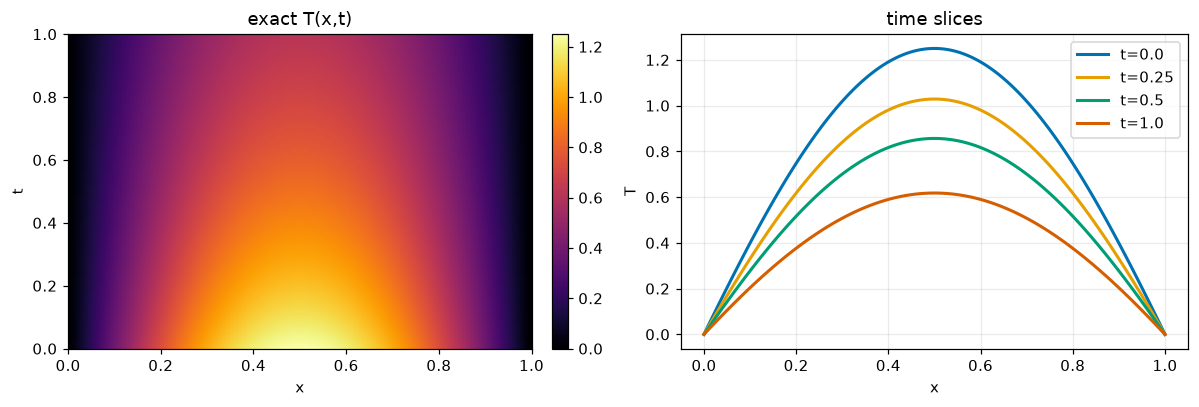

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

# Left: the full exact field.
heat(ax[0], Fexact, [0, 1, 0, 1], "exact T(x,t)", "inferno", "x", "t")

# Right: a few time slices.
for i, t0 in enumerate([0.0, 0.25, 0.5, 1.0]):
    ax[1].plot(xg, T_exact(xg, t0), color=CB[i], lw=2, label=f"t={t0}")
ax[1].set_title("time slices"); 
ax[1].set_xlabel("x")
ax[1].set_ylabel("T")
ax[1].legend()
plt.tight_layout()
plt.show()

A sanity check on the manufactured solution: solve the same PDE with a plain implicit finite-difference scheme (backward Euler), taking boundary and initial values from $T^\star$, and confirm it lands on the exact field. This is the only classical solver in the 1D example. From here on the reference is the exact formula.

In [9]:
# Backward-Euler FD, purely to confirm the manufactured solution is consistent.
def fd_reference_1d(nx=101, nt=400):
    x = np.linspace(0, 1, nx)
    t = np.linspace(0, 1, nt)
    dx, dt = x[1]-x[0], t[1]-t[0]
    lam = alpha*dt/dx**2

    # Tridiagonal system for the implicit update (interior points).
    main = (1 + 2*lam)*np.ones(nx-2)
    off  = -lam*np.ones(nx-3)
    A = np.diag(main) + np.diag(off, 1) + np.diag(off, -1)

    T = T_ic(x).copy()
    sol = [T.copy()]
    for n in range(1, nt):
        rhs = T[1:-1] + dt*q_src(x[1:-1], t[n])
        rhs[0]  += lam*T_exact(0.0, t[n])          # Dirichlet data at x=0
        rhs[-1] += lam*T_exact(1.0, t[n])          # Dirichlet data at x=1
        Tin = np.linalg.solve(A, rhs)
        T = np.concatenate([[T_exact(0.0, t[n])], Tin, [T_exact(1.0, t[n])]])
        sol.append(T.copy())
    return x, t, np.array(sol)

In [10]:
xf, tf_, Ffd = fd_reference_1d()
Xf, Tf_ = np.meshgrid(xf, tf_)

diff = np.abs(Ffd - T_exact(Xf, Tf_)).max()
print("FD vs exact, max abs diff:", round(diff, 5),
      "  (backward Euler is first order in dt, so this is expected)")

FD vs exact, max abs diff: 0.00025   (backward Euler is first order in dt, so this is expected)


## 2. A short PyTorch refresh

A PINN is a small network plus derivatives from autograd. Two features do the work: `requires_grad=True` marks an input so PyTorch records operations on it, and `torch.autograd.grad` differentiates any output with respect to that input. We use it to pull $\partial T/\partial x$ and $\partial^2 T/\partial x^2$ straight out of the network, with no finite differences. If you know PyTorch, skim this.

In [11]:
# Autograd on a known function, to check it against calculus.
# f(x) = sin(2*pi*x)  ->  f'(x) = 2*pi*cos(2*pi*x),  f''(x) = -(2*pi)^2 sin(2*pi*x)
x = torch.linspace(0, 1, 200).reshape(-1, 1).requires_grad_(True)
f = torch.sin(2*np.pi*x)

# First derivative, then differentiate again for the second.
f_x  = torch.autograd.grad(f,   x, torch.ones_like(f),   create_graph=True)[0]
f_xx = torch.autograd.grad(f_x, x, torch.ones_like(f_x), create_graph=True)[0]
print("shapes  f:", tuple(f.shape), " f_x:", tuple(f_x.shape), " f_xx:", tuple(f_xx.shape))

shapes  f: (200, 1)  f_x: (200, 1)  f_xx: (200, 1)


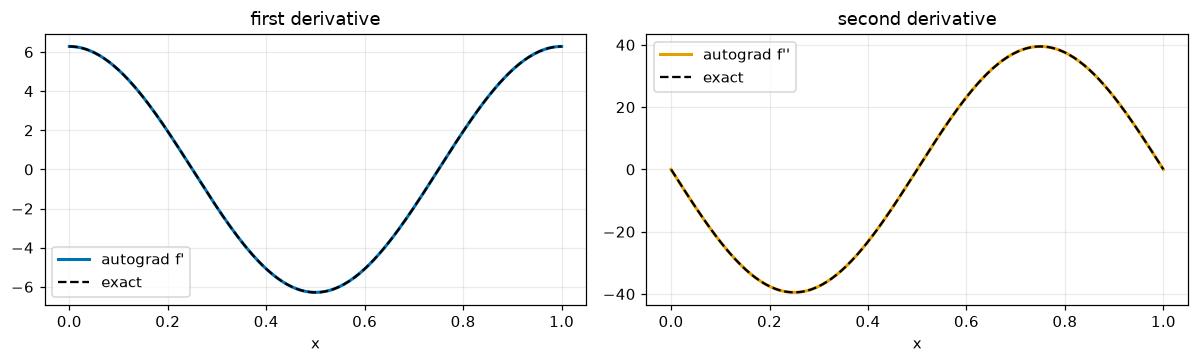

In [12]:
xn = x.detach().numpy().ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))

# First derivative: autograd vs exact.
ax[0].plot(xn, f_x.detach().numpy(), color=CB[0], lw=2, label="autograd f'")
ax[0].plot(xn, 2*np.pi*np.cos(2*np.pi*xn), "--", color="k", label="exact")

# Second derivative: autograd vs exact.
ax[1].plot(xn, f_xx.detach().numpy(), color=CB[1], lw=2, label="autograd f''")
ax[1].plot(xn, -(2*np.pi)**2*np.sin(2*np.pi*xn), "--", color="k", label="exact")

for a in ax: a.legend(); a.set_xlabel("x")
ax[0].set_title("first derivative")
ax[1].set_title("second derivative")
plt.tight_layout(); plt.show()

The network is an ordinary multilayer perceptron: inputs go in, a temperature comes out. We use `tanh` activations because the PDE needs a smooth second derivative, and `tanh` has one everywhere. Section 4.6 shows what happens if you forget that. Two helpers defined here, `MLP` and a one-line `grad` wrapper, get reused unchanged in every example.

In [13]:
class MLP(nn.Module):
    def __init__(self, d_in, width=32, depth=3, d_out=1, act=nn.Tanh):
        super().__init__()

        # Input layer, then (depth-1) hidden layers, then the output layer.
        layers = [nn.Linear(d_in, width), act()]
        for _ in range(depth-1):
            layers += [nn.Linear(width, width), act()]
        layers += [nn.Linear(width, d_out)]
        self.net = nn.Sequential(*layers)

        # Xavier init keeps early-training signals well scaled.
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, X):
        return self.net(X)

In [14]:
# Shorthand: gradient of y with respect to x, keeping the graph for higher orders.
def grad(y, x):
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]

# Quick shape check: 5 points of (x,t) -> 5 temperatures.
demo = MLP(d_in=2, width=32, depth=3)
out = demo(torch.rand(5, 2))
print("MLP(2 -> 1):", demo)
print("batch of 5 (x,t) points -> output shape", tuple(out.shape))

MLP(2 -> 1): MLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
batch of 5 (x,t) points -> output shape (5, 1)


## 3. Building the PINN, piece by piece

A PINN trades the FD grid for three sets of points and a loss that scores physics against them:

- **Collocation points** fill the interior. At each one we ask whether the network satisfies the PDE, and the mismatch is the residual $r=T_t-\alpha T_{xx}-q$.
- **Initial points** sit on $t=0$, where we know $T$.
- **Boundary points** sit on $x=0$ and $x=1$, where we know $T$.

The total loss is a weighted sum:

$$\mathcal{L}=\mathcal{L}_{\text{pde}}+\lambda_{\text{ic}}\,\mathcal{L}_{\text{ic}}+\lambda_{\text{bc}}\,\mathcal{L}_{\text{bc}} .$$

Each term is a mean of squares over its point set. The weights $\lambda$ matter, and Section 4 pokes at them. First, look at the points.

In [15]:
set_seed(0)
Ncol, Nic, Nbc = 2000, 200, 200

# Interior collocation points (x,t).
Xc = torch.rand(Ncol, 2)

# Initial-condition points at t=0, with their target temperatures.
xic = torch.rand(Nic, 1)
Xic = torch.cat([xic, torch.zeros_like(xic)], 1)
Tic_target = torch.tensor(T_ic(xic.numpy()), dtype=torch.float32)

# Boundary points on the two edges x=0 and x=1.
tbc = torch.rand(Nbc, 1)
Xb0 = torch.cat([torch.zeros_like(tbc), tbc], 1)
Xb1 = torch.cat([torch.ones_like(tbc),  tbc], 1)

print("collocation:", tuple(Xc.shape), "| IC:", tuple(Xic.shape),
      "| BC each side:", tuple(Xb0.shape))

collocation: (2000, 2) | IC: (200, 2) | BC each side: (200, 2)


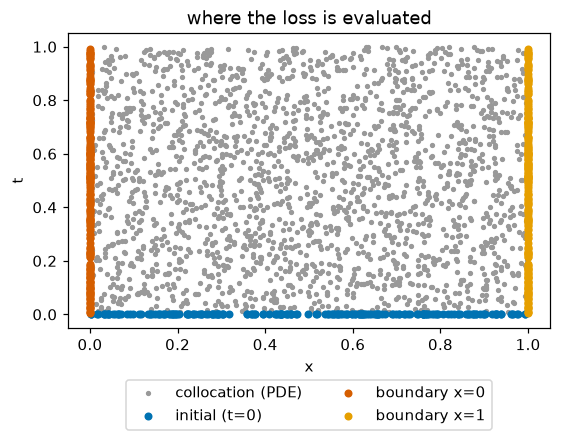

In [16]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.scatter(Xc[:,0],  Xc[:,1],  s=6,  color="0.6", label="collocation (PDE)")
ax.scatter(Xic[:,0], Xic[:,1], s=18, color=CB[0], label="initial (t=0)")
ax.scatter(Xb0[:,0], Xb0[:,1], s=18, color=CB[3], label="boundary x=0")
ax.scatter(Xb1[:,0], Xb1[:,1], s=18, color=CB[1], label="boundary x=1")

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_title("where the loss is evaluated")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2); ax.grid(False)
plt.tight_layout()
plt.show()

The residual is the physics term. Feed collocation points through the network, get $T_t$ and $T_{xx}$ from autograd, and combine them with the known source into $r=T_t-\alpha T_{xx}-q$. On an untrained network the residual is large and structureless: training drives it to zero.

In [17]:
# The PDE residual r = T_t - alpha*T_xx - q, evaluated at points X = (x,t).
def pde_residual(net, X):
    X = X.clone().requires_grad_(True)
    T = net(X)

    # First derivatives, then the second derivative in x.
    g = grad(T, X)
    T_x, T_t = g[:, 0:1], g[:, 1:2]
    T_xx = grad(T_x, X)[:, 0:1]

    # Known source term q(x,t).
    q = torch.exp(-X[:,1:2])*torch.sin(np.pi*X[:,0:1])*(alpha*np.pi**2 - 1) + 2*alpha*beta
    return T_t - alpha*T_xx - q

In [18]:
# On a fresh network the residual is large and unstructured.
set_seed(0)
untrained = MLP(2, 32, 3)
r0 = pde_residual(untrained, Xc)
print("residual shape:", tuple(r0.shape),
      "| a few values:", np.round(r0[:4,0].detach().numpy(), 3))

# Evaluate the residual on a regular grid so we can map it.
n = 60; g_ = np.linspace(0, 1, n)
Xg, Tg = np.meshgrid(g_, g_)
grid = torch.tensor(np.stack([Xg.ravel(), Tg.ravel()], 1), dtype=torch.float32)
R = pde_residual(untrained, grid).detach().numpy().reshape(n, n)

residual shape: (2000, 1) | a few values: [-2.426 -1.821 -2.371 -2.241]


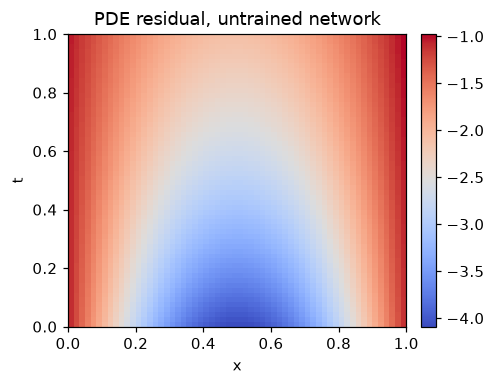

In [19]:
fig, ax = plt.subplots(figsize=(4.6, 3.6))
heat(ax, R, [0,1,0,1], "PDE residual, untrained network", "coolwarm", "x", "t")
plt.tight_layout()
plt.show()

Now the training loop. `train_pinn` runs Adam, then an optional short L-BFGS polish, and records each loss term. It is written once and reused verbatim in Examples 2 and 3: only the `loss_fn` changes.

In [20]:
def train_pinn(net, loss_fn, adam_iters=2500, lr=3e-3, lbfgs_iters=0, log_every=250):
    hist = {}

    # Phase 1: Adam.
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for it in range(adam_iters):
        opt.zero_grad()
        total, terms = loss_fn()
        total.backward()
        opt.step(); ex_pinn_hook(net, it, terms)  # hook: animation snapshot and checkpoint (Example 1 only)

        # Record each loss term every log_every steps.
        if it % log_every == 0 or it == adam_iters-1:
            for k, v in terms.items():
                hist.setdefault(k, []).append((it, float(v.detach())))

    # Phase 2 (optional): a short L-BFGS polish using curvature.
    if lbfgs_iters > 0:
        opt2 = torch.optim.LBFGS(net.parameters(), max_iter=lbfgs_iters,
                                 line_search_fn="strong_wolfe")
        def closure():
            opt2.zero_grad()
            t, _ = loss_fn(); t.backward()
            return t
        opt2.step(closure); ex_pinn_hook(net, adam_iters + lbfgs_iters, loss_fn()[1], final=True)  # hook: last snapshot after L-BFGS

        total, terms = loss_fn()
        for k, v in terms.items():
            hist.setdefault(k, []).append((adam_iters+lbfgs_iters, float(v.detach())))
    return hist

In [21]:
# Loss weights for the initial and boundary terms.
lam_ic, lam_bc = 10.0, 10.0

set_seed(0)
pinn = MLP(2, 32, 3)

# Example 1 loss: PDE residual + weighted IC + weighted BC.
def loss_ex1():
    L_pde = (pde_residual(pinn, Xc)**2).mean()
    L_ic  = ((pinn(Xic) - Tic_target)**2).mean()
    L_bc  = (pinn(Xb0)**2).mean() + (pinn(Xb1)**2).mean()
    total = L_pde + lam_ic*L_ic + lam_bc*L_bc
    return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "total": total}

t0, terms0 = loss_ex1()
print("initial loss terms:", {k: round(float(v), 4) for k, v in terms0.items()})

initial loss terms: {'pde': 5.7828, 'ic': 1.227, 'bc': 0.2935, 'total': 20.9874}


<cell>:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print("initial loss terms:", {k: round(float(v), 4) for k, v in terms0.items()})


**Training hook.** Before training Example 1, I attach a small hook to `train_pinn`: it is called after every Adam step and once after the L-BFGS polish. It records the three loss terms at every iteration, the predicted field on the 120×120 grid every 50 iterations for the training animation, and a checkpoint every 500 iterations. It only evaluates the network and draws no random numbers, so the training is the same as without it, and it switches itself off after Example 1.

In [22]:
from pathlib import Path
EX_CKPT = MODELS_DIR / "checkpoints"; EX_CKPT.mkdir(parents=True, exist_ok=True)
anim_snaps, anim_terms, EX_HOOK_ACTIVE = [], [], [True]
anim_pts = torch.tensor(np.stack([XX.ravel(), TT.ravel()], 1), dtype=torch.float32)
def ex_pinn_hook(net, it, terms, final=False):
    if not EX_HOOK_ACTIVE[0]: return
    anim_terms.append((float(terms["pde"]), float(terms["ic"]), float(terms["bc"])))
    if final or it % 50 == 0:
        with torch.no_grad(): Fp = net(anim_pts).numpy().reshape(nt, nx)
        anim_snaps.append(dict(it=it, F=Fp, terms=list(anim_terms)))
    if final or it % 500 == 0: torch.save(net.state_dict(), EX_CKPT / f"pinn_ex1_it{it:04d}.pth")
    if final: EX_HOOK_ACTIVE[0] = False

In [23]:
# Trains the Example 1 PINN: roughly 20 to 60 s on a Colab CPU.
import time
t0 = time.time()
hist = train_pinn(pinn, loss_ex1, adam_iters=2500, lr=3e-3, lbfgs_iters=25)
print(f"trained in {time.time()-t0:.1f}s")

trained in 9.0s


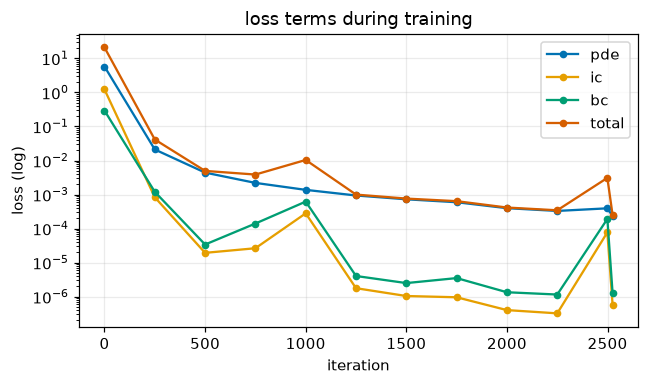

final: {'pde': '2.32e-04', 'ic': '5.78e-07', 'bc': '1.27e-06', 'total': '2.51e-04'}


In [24]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for i, k in enumerate(["pde", "ic", "bc", "total"]):
    it, val = zip(*hist[k])
    ax.semilogy(it, val, "o-", color=CB[i], label=k, ms=4)

ax.set_xlabel("iteration")
ax.set_ylabel("loss (log)")
ax.set_title("loss terms during training")
ax.legend()
plt.tight_layout(); plt.show()
print("final:", {k: f"{hist[k][-1][1]:.2e}" for k in hist})

Prediction against the exact field, plus the residual after training. Both maps should be small and featureless. If the residual is small but the error is not, the network is solving a nearby wrong problem, usually a boundary or initial term that is under-weighted.

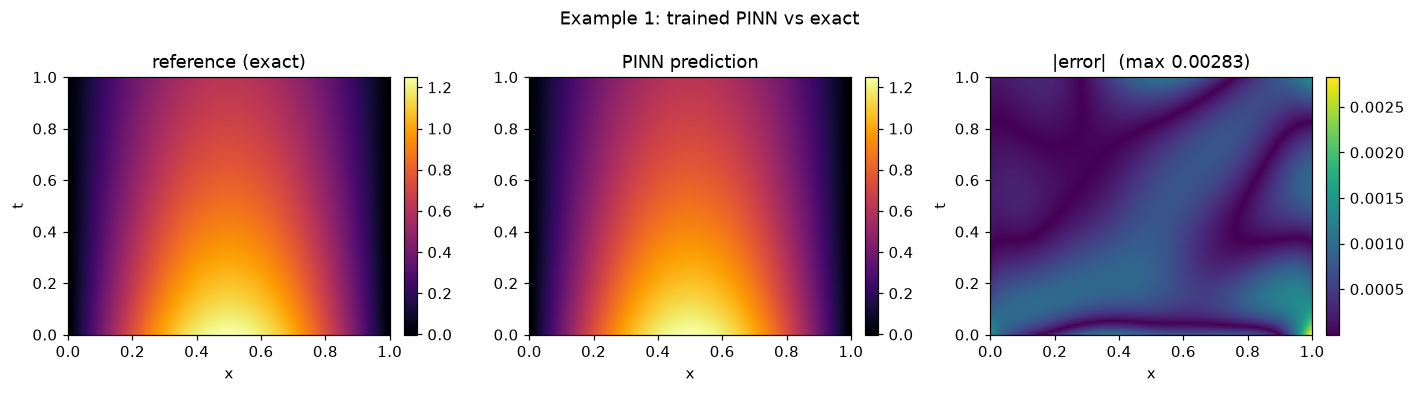

In [25]:
# Predict on the full grid and compare to the exact field.
with torch.no_grad():
    grid_xt = torch.tensor(np.stack([XX.ravel(), TT.ravel()], 1), dtype=torch.float32)
    Fp = pinn(grid_xt).numpy().reshape(nt, nx)

panels3(Fexact, Fp, [0,1,0,1], "Example 1: trained PINN vs exact", "inferno", "x", "t")

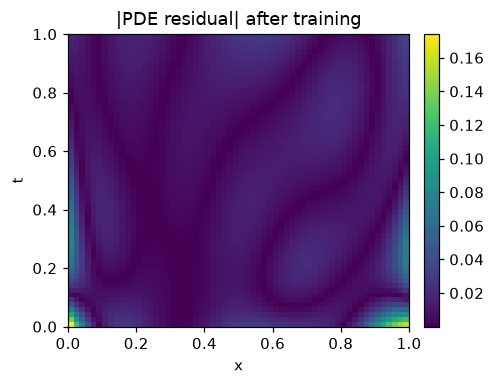

max|error| = 0.0028   RMSE = 0.0005


In [26]:
# Residual after training should be near zero everywhere.
R_after = pde_residual(pinn, grid).detach().numpy().reshape(n, n)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
heat(ax, np.abs(R_after), [0,1,0,1], "|PDE residual| after training", "viridis", "x", "t")
plt.tight_layout(); plt.show()

err = np.abs(Fp - Fexact)
print(f"max|error| = {err.max():.4f}   RMSE = {np.sqrt((err**2).mean()):.4f}")

## 4. Practical experiments

The mechanics work. Making a PINN work *reliably* is mostly about the knobs around it: loss weights, how many points and where, which optimizer, and which activation. Six short studies follow, each with an expected outcome and a diagnostic. All reuse one small, fast helper (`quick_pinn`).

In [27]:
# Small, fast PINN trainer for the experiments (Example-1 problem, tunable knobs).
def quick_pinn(width=24, depth=2, act=nn.Tanh, Ncol=1500, Nbc=150, Nic=150,
               lam_ic=10.0, lam_bc=10.0, adam_iters=800, lbfgs_iters=0,
               use_ic=True, seed=0):
    set_seed(seed)

    # Interior, initial, and boundary points.
    Xc  = torch.rand(Ncol, 2)
    xic = torch.rand(Nic, 1); Xic = torch.cat([xic, torch.zeros_like(xic)], 1)
    yic = torch.tensor(T_ic(xic.numpy()), dtype=torch.float32)
    tbc = torch.rand(Nbc, 1)
    Xb0 = torch.cat([torch.zeros_like(tbc), tbc], 1)
    Xb1 = torch.cat([torch.ones_like(tbc),  tbc], 1)

    net = MLP(2, width, depth, act=act)

    # Same loss shape as Example 1 (IC can be switched off for one study).
    def loss_fn():
        L_pde = (pde_residual(net, Xc)**2).mean()
        L_ic  = ((net(Xic) - yic)**2).mean() if use_ic else torch.zeros(())
        L_bc  = (net(Xb0)**2).mean() + (net(Xb1)**2).mean()
        total = L_pde + lam_ic*L_ic + lam_bc*L_bc
        return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "total": total}

    hist = train_pinn(net, loss_fn, adam_iters=adam_iters, lr=3e-3, lbfgs_iters=lbfgs_iters)

    # Error against the exact field on a 60x60 grid.
    m = 60
    gg = np.linspace(0, 1, m)
    Xg, Tg = np.meshgrid(gg, gg)
    with torch.no_grad():
        pts = torch.tensor(np.stack([Xg.ravel(), Tg.ravel()], 1), dtype=torch.float32)
        Fp = net(pts).numpy().reshape(m, m)
    ref = T_exact(Xg, Tg)
    e = np.abs(Fp - ref)

    return dict(net=net, hist=hist, max_err=float(e.max()),
                rmse=float(np.sqrt((e**2).mean())), Fp=Fp, ref=ref)

print("quick_pinn ready")

quick_pinn ready


### 4.1 Loss weighting

The PDE, IC, and BC terms compete. If the boundary and initial weights are too small, the network lowers the interior residual by drifting away from the known data. Expect the error to fall as the weights come into balance, then plateau.

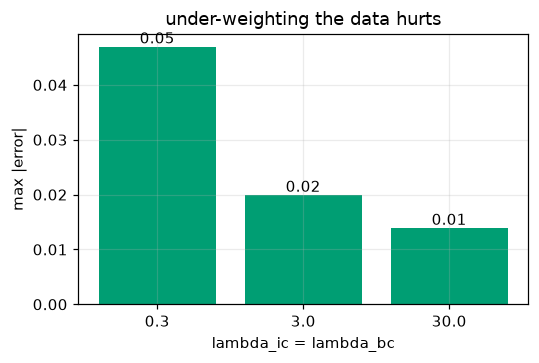

{0.3: 0.047, 3.0: 0.02, 30.0: 0.014}


In [28]:
# Three weight levels. Trains three small networks: about 15 to 30 s total.
lams = [0.3, 3.0, 30.0]
res = [quick_pinn(lam_ic=L, lam_bc=L, adam_iters=800) for L in lams]

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.bar([str(L) for L in lams], [r["max_err"] for r in res], color=CB[2])
for L, r in zip(lams, res):
    ax.text(str(L), r["max_err"], f"{r['max_err']:.2f}", ha="center", va="bottom")
ax.set_xlabel("lambda_ic = lambda_bc"); ax.set_ylabel("max |error|")
ax.set_title("under-weighting the data hurts")
plt.tight_layout(); plt.show()

print({L: round(r["max_err"], 3) for L, r in zip(lams, res)})

### 4.2 Number of collocation points

Too few interior points and the physics is enforced on a sparse sample, so the network can cheat between them. Expect error to drop as points increase, with diminishing returns.

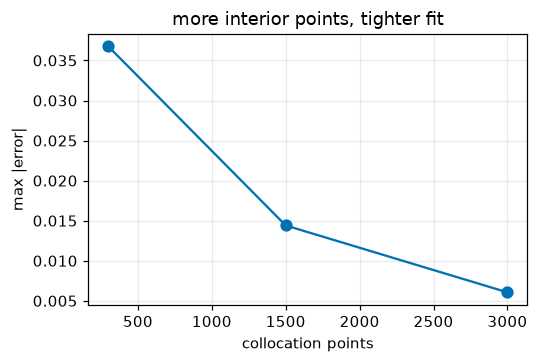

{300: 0.037, 1500: 0.014, 3000: 0.006}


In [29]:
# Three collocation counts. Trains three small networks: about 20 to 40 s total.
counts = [300, 1500, 3000]
res = [quick_pinn(Ncol=nc, adam_iters=800) for nc in counts]

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(counts, [r["max_err"] for r in res], "o-", color=CB[0], ms=7)
ax.set_xlabel("collocation points"); ax.set_ylabel("max |error|")
ax.set_title("more interior points, tighter fit")
plt.tight_layout(); plt.show()

print({nc: round(r["max_err"], 3) for nc, r in zip(counts, res)})

### 4.3 Boundary sampling

The boundary carries the Dirichlet data. Starve it and the edges wander. Compare a barely-sampled boundary against a well-sampled one.

In [30]:
# Two boundary sample sizes. Trains two small networks: about 10 to 20 s total.
for nb in [8, 200]:
    r = quick_pinn(Nbc=nb, adam_iters=800)
    print(f"Nbc={nb:4d}  ->  max|error| = {r['max_err']:.3f}")

Nbc=   8  ->  max|error| = 0.027


Nbc= 200  ->  max|error| = 0.016


### 4.4 Initial-condition sampling

The IC anchors the whole time evolution. With too few IC points the early-time field is wrong, and that error propagates forward in $t$.

In [31]:
# Two IC sample sizes. Trains two small networks: about 10 to 20 s total.
for ni in [5, 200]:
    r = quick_pinn(Nic=ni, adam_iters=800)
    print(f"Nic={ni:4d}  ->  max|error| = {r['max_err']:.3f}")

Nic=   5  ->  max|error| = 0.039


Nic= 200  ->  max|error| = 0.012


### 4.5 Adam versus Adam then L-BFGS

Adam gets close quickly but stalls on a flat, ill-conditioned loss. A short L-BFGS run afterward uses curvature to polish the last digits. Expect the total loss to drop sharply at the handoff.

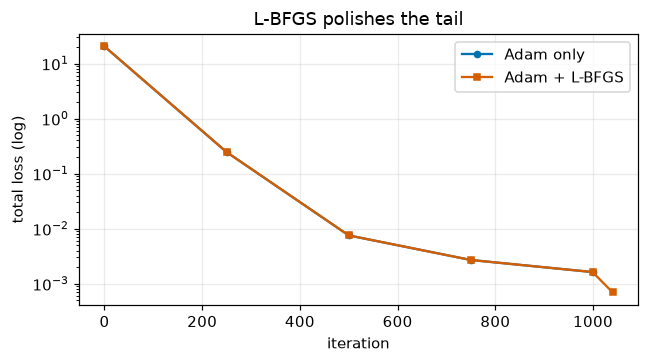

Adam only   max|error| = 0.0125
Adam+L-BFGS max|error| = 0.0100


In [32]:
# One Adam-only run and one Adam+L-BFGS run: about 15 to 30 s total.
ra = quick_pinn(adam_iters=1000, lbfgs_iters=0)
rb = quick_pinn(adam_iters=1000, lbfgs_iters=40)

fig, ax = plt.subplots(figsize=(6, 3.4))
it, v = zip(*ra["hist"]["total"]); ax.semilogy(it, v, "o-", color=CB[0], label="Adam only", ms=4)
it, v = zip(*rb["hist"]["total"]); ax.semilogy(it, v, "s-", color=CB[3], label="Adam + L-BFGS", ms=4)
ax.set_xlabel("iteration"); ax.set_ylabel("total loss (log)"); ax.legend()
ax.set_title("L-BFGS polishes the tail")
plt.tight_layout(); plt.show()

print(f"Adam only   max|error| = {ra['max_err']:.4f}")
print(f"Adam+L-BFGS max|error| = {rb['max_err']:.4f}")

### 4.6 A deliberate failure: the wrong activation

The residual needs $T_{xx}$. A ReLU network is piecewise linear, so its second derivative is zero almost everywhere. The diffusion term vanishes from the residual, the network solves a different equation, and the fit falls apart. This is the most common silent PINN bug: the code runs, the loss even goes down, and the answer is wrong.

tanh  max|error| = 0.018
ReLU  max|error| = 3.175   mean|T_xx| (ReLU) = 0.00e+00


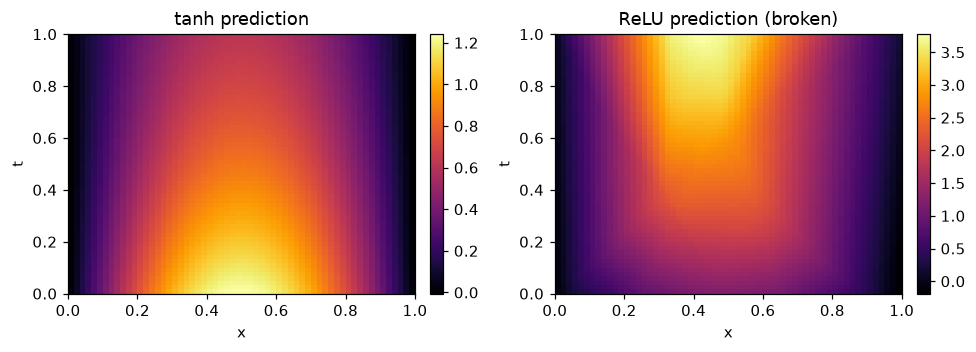

In [33]:
# Compare tanh against ReLU: about 10 to 20 s total.
rt = quick_pinn(act=nn.Tanh, adam_iters=600)
rr = quick_pinn(act=nn.ReLU, adam_iters=600)

# Show that a ReLU network carries almost no second derivative.
Xs = torch.rand(500, 2, requires_grad=True)
Ts = rr["net"](Xs)
Txx = grad(grad(Ts, Xs)[:,0:1], Xs)[:,0:1]
print(f"tanh  max|error| = {rt['max_err']:.3f}")
print(f"ReLU  max|error| = {rr['max_err']:.3f}   mean|T_xx| (ReLU) = {Txx.abs().mean():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
heat(ax[0], rt["Fp"], [0,1,0,1], "tanh prediction", "inferno", "x", "t")
heat(ax[1], rr["Fp"], [0,1,0,1], "ReLU prediction (broken)", "inferno", "x", "t")
plt.tight_layout(); plt.show()

### PINN debugging checklist

When a PINN misbehaves, the symptom usually points straight at the cause.

| Symptom | Likely cause | Diagnostic |
|---|---|---|
| Residual small, error large | IC or BC under-weighted | raise $\lambda_{\text{ic}},\lambda_{\text{bc}}$; plot error vs residual |
| Edges or $t=0$ wrong | too few BC or IC points | plot the point sets; add points where it is wrong |
| Interior wavy between points | too few collocation points | increase `Ncol` |
| Loss stalls high | Adam plateau, or bad scaling | add L-BFGS; non-dimensionalize (Section 6) |
| Loss falls, answer nonsense | non-smooth activation, or missing term in the residual | check activation is `tanh`; re-derive the residual |
| NaNs | learning rate too high, or a $1/x$ singularity sampled | lower `lr`; keep collocation off singular points |

The habit that catches most of these: plot the residual field and the error field side by side. They tell different stories.

## 5. Physics plus data

Industrial problems rarely hand you clean boundary data. More often you have a governing equation you half-trust and a handful of noisy sensor readings. A PINN takes both: add a data term that pulls the network toward the measurements, alongside the physics.

$$\mathcal{L}_{\text{total}}=\mathcal{L}_{\text{pde}}+\lambda_{\text{ic}}\mathcal{L}_{\text{ic}}+\lambda_{\text{bc}}\mathcal{L}_{\text{bc}}+\lambda_{\text{data}}\mathcal{L}_{\text{data}} .$$

We place a few sensors, read the exact field at those spots, add noise, and let the network balance physics against observations. Stage 2 turns this around: hold the data fixed and solve for an *unknown parameter* instead.

In [34]:
# A few noisy sensors scattered in the (x,t) domain.
set_seed(3)
Nsens = 12
xs = torch.rand(Nsens, 1); ts = torch.rand(Nsens, 1)
Xdata = torch.cat([xs, ts], 1)

# Readings: the exact field at those spots, plus measurement noise.
noise = 0.02
ydata = torch.tensor(T_exact(xs.numpy(), ts.numpy()), dtype=torch.float32) \
        + noise*torch.randn(Nsens, 1)
print("sensor readings:", tuple(Xdata.shape), "| noise std:", noise)

sensor readings: (12, 2) | noise std: 0.02


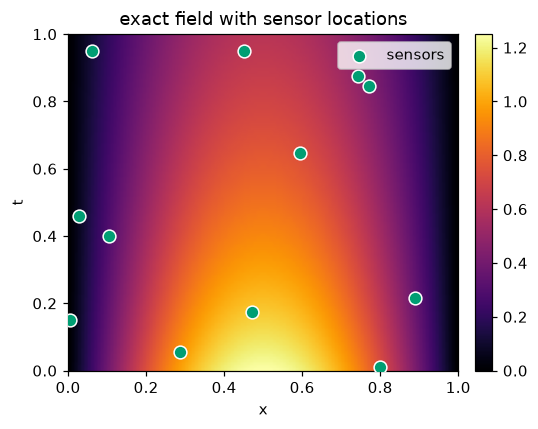

In [35]:
fig, ax = plt.subplots(figsize=(5, 4))
heat(ax, Fexact, [0,1,0,1], "exact field with sensor locations", "inferno", "x", "t")
ax.scatter(xs, ts, s=70, edgecolor="w", color=CB[2], zorder=3, label="sensors")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

In [36]:
set_seed(0); pinn_d = MLP(2, 32, 3)
lam_data = 20.0

# Same physics loss as Example 1, plus a data term pulling toward the sensors.
def loss_data():
    L_pde = (pde_residual(pinn_d, Xc)**2).mean()
    L_ic  = ((pinn_d(Xic) - Tic_target)**2).mean()
    L_bc  = (pinn_d(Xb0)**2).mean() + (pinn_d(Xb1)**2).mean()
    L_dat = ((pinn_d(Xdata) - ydata)**2).mean()
    total = L_pde + lam_ic*L_ic + lam_bc*L_bc + lam_data*L_dat
    return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "data": L_dat, "total": total}

# Trains a network: roughly 20 to 45 s on a Colab CPU.
hist_d = train_pinn(pinn_d, loss_data, adam_iters=2000, lr=3e-3, lbfgs_iters=20)

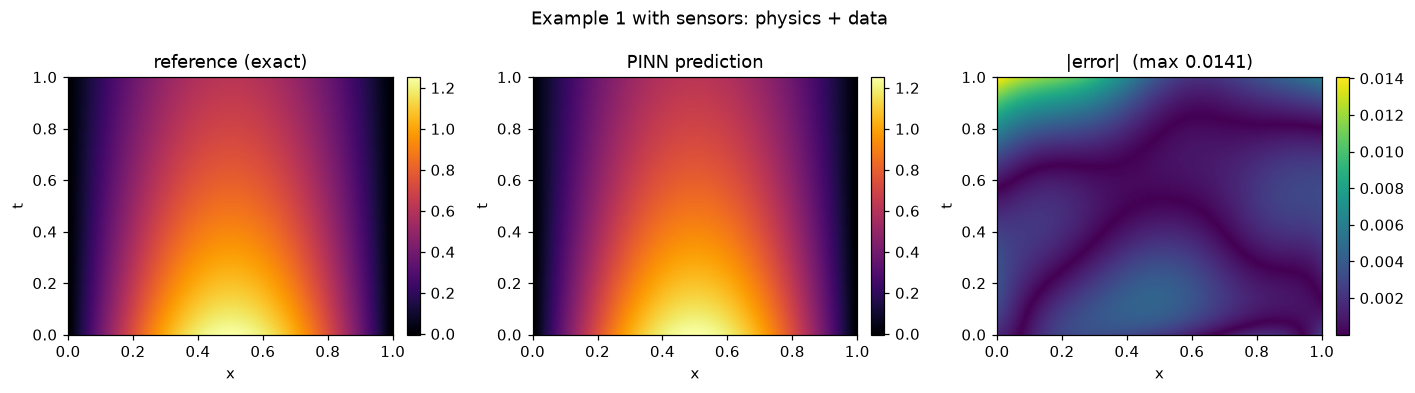

mean |model - sensor| at sensors = 0.0094  (noise std was 0.02)
the model sits near the noisy readings without chasing each one exactly


In [37]:
with torch.no_grad():
    grid_xt = torch.tensor(np.stack([XX.ravel(), TT.ravel()], 1), dtype=torch.float32)
    Fpd = pinn_d(grid_xt).numpy().reshape(nt, nx)
panels3(Fexact, Fpd, [0,1,0,1], "Example 1 with sensors: physics + data", "inferno", "x", "t")

# The fit sits near the noisy readings without chasing each one exactly.
with torch.no_grad():
    fit = (pinn_d(Xdata) - ydata).abs().mean().item()
print(f"mean |model - sensor| at sensors = {fit:.4f}  (noise std was {noise})")
print("the model sits near the noisy readings without chasing each one exactly")

The network does not interpolate the noisy points exactly, and it should not: the physics term regularizes the fit. Turn the data weight up and it hugs the sensors harder, turn it down and physics dominates. That balance is the whole game in data assimilation, and it is the bridge to inverse problems in Stage 2.

## 6. Example 2: a cylindrical fuel pin

Same method, a real geometry. Transient conduction in a cylindrical pin with internal heat generation:

$$\frac{\partial T}{\partial t}=\alpha\left(\frac{\partial^2 T}{\partial r^2}+\frac{1}{r}\frac{\partial T}{\partial r}\right)+\frac{\dot u}{\rho C_p} .$$

Radius $R=3$ mm, a volumetric source from fission, symmetry at the axis $r=0$, and convective cooling at the wall (a Robin condition).

**Why we scale first.** The raw numbers are hostile to a network: $r\sim10^{-3}$, diffusivity $\sim10^{-5}$, temperatures in the tens. Inputs and outputs spanning many orders of magnitude wreck the conditioning, and PINNs are not exempt. So we non-dimensionalize, exactly as before a careful FD run:

$$x=\frac{r}{R}\in[0,1],\quad s=\frac{t}{t_f},\quad \theta=\frac{T-T_0}{T_f-T_0} .$$

This turns the equation into

$$\frac{\partial\theta}{\partial s}=\mathrm{Fo}\left(\frac{\partial^2\theta}{\partial x^2}+\frac{1}{x}\frac{\partial\theta}{\partial x}\right)+S,$$

with a Fourier number $\mathrm{Fo}=\alpha t_f/R^2$ and a source group $S=\dot u\,t_f/[\rho C_p (T_f-T_0)]$. The wall carries a Biot number $\mathrm{Bi}=hR/\lambda$:

$$\left.\frac{\partial\theta}{\partial x}\right|_{x=1}=\mathrm{Bi}\,(1-\theta),\qquad \left.\frac{\partial\theta}{\partial x}\right|_{x=0}=0 .$$

Here $\mathrm{Bi}\approx0.05$, so the pin is nearly isothermal across its radius and the approach to steady state is set by the lumped time $\tau=\rho C_p R/(2h)\approx 7$ s. We model a $t_f=2$ s window, which keeps a strong temporal gradient in view.

In [38]:
# Physical parameters (from the reference FD script).
rho, Cp, lam_c, u = 19100., 140., 33., 1e7
T0, Tfl, R, h = 20., 60., 0.003, 600.
tf_win = 2.0

# Diffusivity, volumetric source, and the dimensionless groups.
D = lam_c/(rho*Cp); Qvol = u/(rho*Cp)
Fo = D*tf_win/R**2; Bi = h*R/lam_c; S = Qvol*tf_win/(Tfl - T0)

print(f"D = {D:.3e} m^2/s   Qvol = {Qvol:.3f} K/s")
print(f"diffusion time R^2/D = {R**2/D:.2f} s   lumped time rho*Cp*R/(2h) = {rho*Cp*R/(2*h):.2f} s")
print(f"Fo = {Fo:.3f}   Bi = {Bi:.4f}   S = {S:.4f}")

D = 1.234e-05 m^2/s   Qvol = 3.740 K/s
diffusion time R^2/D = 0.73 s   lumped time rho*Cp*R/(2h) = 6.68 s
Fo = 2.742   Bi = 0.0545   S = 0.1870


In [39]:
# Backward-Euler FD reference (implicit, tridiagonal). field[time, radius].
def fd_cylinder(N=25, dt=1e-3, tf=2.0):
    r = np.linspace(0, R, N+1); dr = R/N; M = int(round(tf/dt)); ri = r[1:N]

    # Tridiagonal coefficients for the interior nodes.
    a = (dt*D/dr**2)*(-1 + dr/(2*ri))          # sub-diagonal
    b = (1 + 2*D*dt/dr**2)*np.ones(N-1)         # diagonal
    c = (dt*D/dr**2)*(-1 - dr/(2*ri))           # super-diagonal
    d = (Qvol*dt)*np.ones(N-1)                   # source

    # Fold the two boundary conditions into the first and last rows.
    b[0]  += a[0]                                 # axis symmetry
    b[-1] += lam_c*c[-1]/(lam_c + h*dr)           # Robin wall
    d[-1] -= h*dr*Tfl*c[-1]/(lam_c + h*dr)
    A = np.diag(b) + np.diag(a[1:], -1) + np.diag(c[:-1], 1)

    # March in time.
    T = T0*np.ones(N+1); field = [T.copy()]; times = [0.0]
    for n in range(1, M+1):
        Tin = np.linalg.solve(A, T[1:-1] + d)
        Tn = T.copy(); Tn[1:-1] = Tin
        Tn[0]  = Tn[1]                                       # axis
        Tn[-1] = (lam_c*Tn[-2] + h*Tfl*dr)/(lam_c + h*dr)    # Robin wall
        T = Tn; field.append(T.copy()); times.append(n*dt)
    return r, np.array(times), np.array(field)

In [40]:
# This FD reference marches 2000 small steps: a few seconds.
r_fd, t_fd, T_fd = fd_cylinder()
print("FD field:", T_fd.shape, "| T range", round(T_fd.min(),2), "to", round(T_fd.max(),2))

FD field: (2001, 26) | T range 20.0 to 37.19


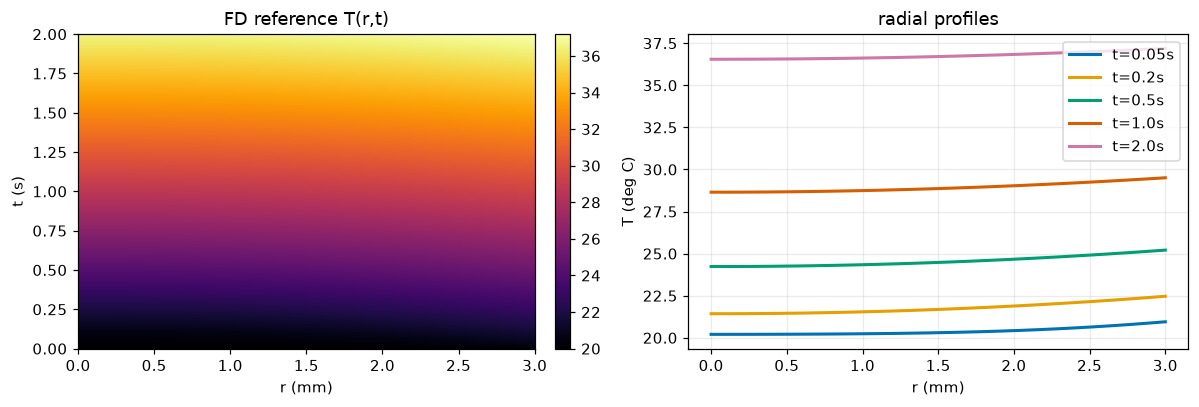

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
heat(ax[0], T_fd, [0, R*1e3, 0, tf_win], "FD reference T(r,t)", "inferno", "r (mm)", "t (s)")

# Radial profiles at a few times.
for i, ts0 in enumerate([0.05, 0.2, 0.5, 1.0, 2.0]):
    k = np.argmin(np.abs(t_fd - ts0))
    ax[1].plot(r_fd*1e3, T_fd[k], color=CB[i], lw=2, label=f"t={ts0}s")
ax[1].set_xlabel("r (mm)"); ax[1].set_ylabel("T (deg C)"); ax[1].set_title("radial profiles")
ax[1].legend(); plt.tight_layout(); plt.show()

**What changes, and what does not.** This is the point of the whole session.

| Reused unchanged from Example 1 | Modified for the cylinder |
|---|---|
| `MLP`, `grad`, `train_pinn` | the residual: now $\theta_s-\mathrm{Fo}(\theta_{xx}+\theta_x/x)-S$ |
| the weighted-sum loss structure | boundary terms: axis symmetry and a Robin wall |
| `heat`, `panels3` plotting | the sampling domain $(x,s)$, kept off the axis |
| Adam then L-BFGS | the reference: FD instead of a manufactured formula |

The network, the derivatives, and the optimizer are identical. Only the equation and its boundary terms move.

In [42]:
set_seed(0)
xmin = 0.02                     # keep collocation off the 1/x singularity at the axis
Nc, Ni, Na, Nw = 2500, 300, 300, 300

# Interior collocation in the dimensionless domain (x = r/R, s = t/tf).
xcol = torch.rand(Nc, 1)*(1-xmin) + xmin
scol = torch.rand(Nc, 1)
Xcyl = torch.cat([xcol, scol], 1)

# Initial (s=0), axis (x=0), and wall (x=1) point sets.
xi = torch.rand(Ni, 1); Xic_c = torch.cat([xi, torch.zeros_like(xi)], 1)
sa = torch.rand(Na, 1); Xax   = torch.cat([torch.zeros_like(sa), sa], 1)
sw = torch.rand(Nw, 1); Xwall = torch.cat([torch.ones_like(sw),  sw], 1)

print("collocation:", tuple(Xcyl.shape), "| IC:", tuple(Xic_c.shape),
      "| axis:", tuple(Xax.shape), "| wall:", tuple(Xwall.shape))

collocation: (2500, 2) | IC: (300, 2) | axis: (300, 2) | wall: (300, 2)


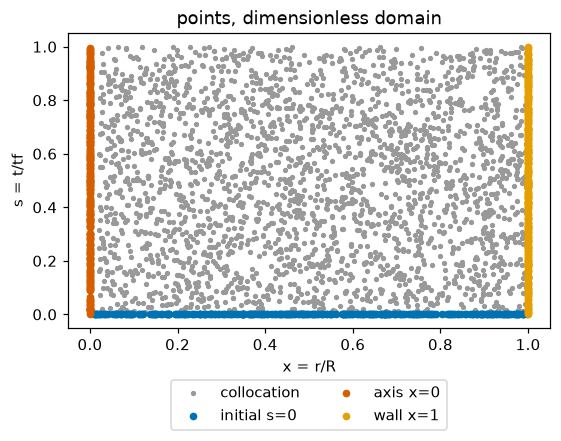

In [43]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.scatter(Xcyl[:,0],  Xcyl[:,1],  s=6,  color="0.6", label="collocation")
ax.scatter(Xic_c[:,0], Xic_c[:,1], s=16, color=CB[0], label="initial s=0")
ax.scatter(Xax[:,0],   Xax[:,1],   s=16, color=CB[3], label="axis x=0")
ax.scatter(Xwall[:,0], Xwall[:,1], s=16, color=CB[1], label="wall x=1")

ax.set_xlabel("x = r/R"); ax.set_ylabel("s = t/tf"); ax.set_title("points, dimensionless domain")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.15), ncol=2); ax.grid(False)
plt.tight_layout(); plt.show()

In [44]:
set_seed(0); pinn_c = MLP(2, 32, 3)

# Cylindrical residual: theta_s - Fo*(theta_xx + theta_x/x) - S.
def residual_cyl(net, X):
    X = X.clone().requires_grad_(True)
    th = net(X); g = grad(th, X); th_x, th_s = g[:,0:1], g[:,1:2]
    th_xx = grad(th_x, X)[:,0:1]; x = X[:,0:1]
    return th_s - Fo*(th_xx + th_x/x) - S

# Loss: PDE + initial + axis symmetry + Robin wall.
def loss_cyl():
    L_pde = (residual_cyl(pinn_c, Xcyl)**2).mean()
    L_ic  = (pinn_c(Xic_c)**2).mean()                     # theta = 0 at s=0

    Xa = Xax.clone().requires_grad_(True)                 # axis: theta_x = 0
    L_ax = (grad(pinn_c(Xa), Xa)[:,0:1]**2).mean()

    Xw = Xwall.clone().requires_grad_(True)               # wall: theta_x = Bi(1-theta)
    thw = pinn_c(Xw); thw_x = grad(thw, Xw)[:,0:1]
    L_wall = ((thw_x - Bi*(1 - thw))**2).mean()

    total = L_pde + 10*L_ic + 10*L_ax + 10*L_wall
    return total, {"pde": L_pde, "ic": L_ic, "ax": L_ax, "wall": L_wall, "total": total}

In [45]:
# Trains the cylindrical PINN: roughly 30 to 60 s on a Colab CPU.
# train_pinn is reused unchanged from Example 1.
t0 = time.time()
hist_c = train_pinn(pinn_c, loss_cyl, adam_iters=2500, lr=3e-3, lbfgs_iters=25)
print(f"trained in {time.time()-t0:.1f}s")

trained in 10.6s


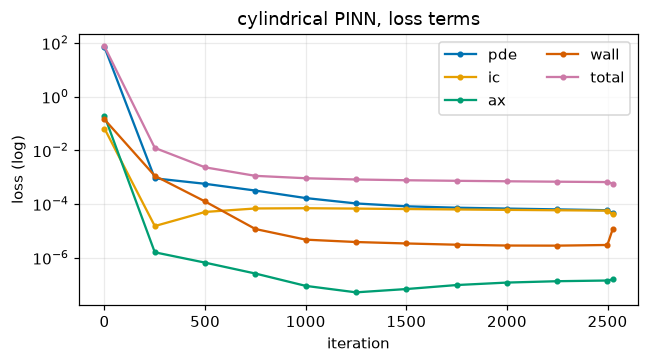

In [46]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for i, k in enumerate(["pde", "ic", "ax", "wall", "total"]):
    it, v = zip(*hist_c[k]); ax.semilogy(it, v, "o-", color=CB[i], label=k, ms=3)
ax.set_xlabel("iteration"); ax.set_ylabel("loss (log)"); ax.legend(ncol=2)
ax.set_title("cylindrical PINN, loss terms"); plt.tight_layout(); plt.show()

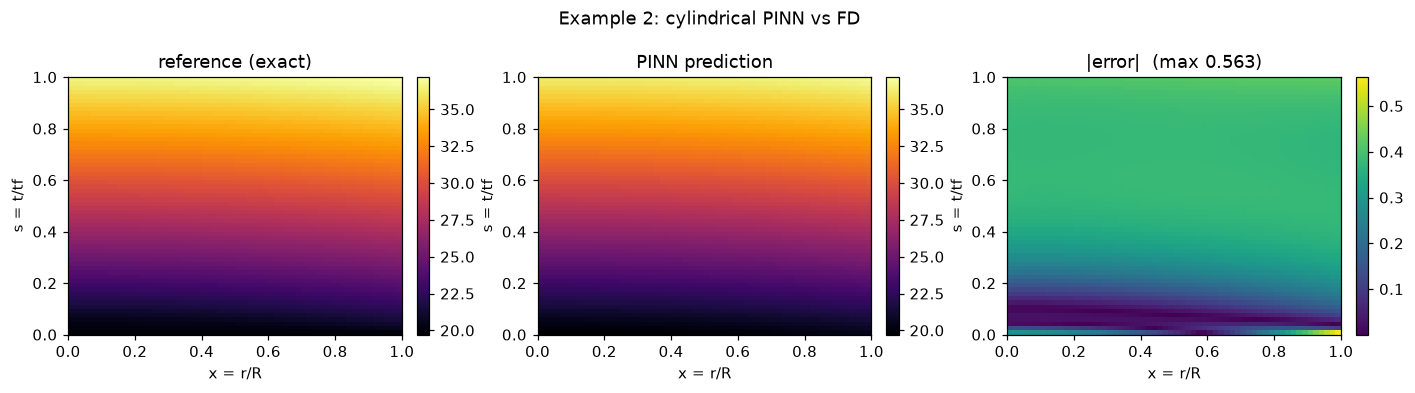

In [47]:
# Compare against the FD reference in physical units.
from scipy.interpolate import RegularGridInterpolator
xg = np.linspace(xmin, 1, 60); sg = np.linspace(0, 1, 60)
Xg, Sg = np.meshgrid(xg, sg)

# PINN prediction, mapped back to temperature.
with torch.no_grad():
    pts = torch.tensor(np.stack([Xg.ravel(), Sg.ravel()], 1), dtype=torch.float32)
    th_p = pinn_c(pts).numpy().reshape(60, 60)
T_pred = th_p*(Tfl - T0) + T0

# FD reference interpolated onto the same (x,s) grid.
interp = RegularGridInterpolator((t_fd, r_fd), T_fd)
T_ref = interp(np.stack([(Sg*tf_win).ravel(), (Xg*R).ravel()], 1)).reshape(60, 60)

panels3(T_ref, T_pred, [0, 1, 0, 1], "Example 2: cylindrical PINN vs FD",
        "inferno", "x = r/R", "s = t/tf")

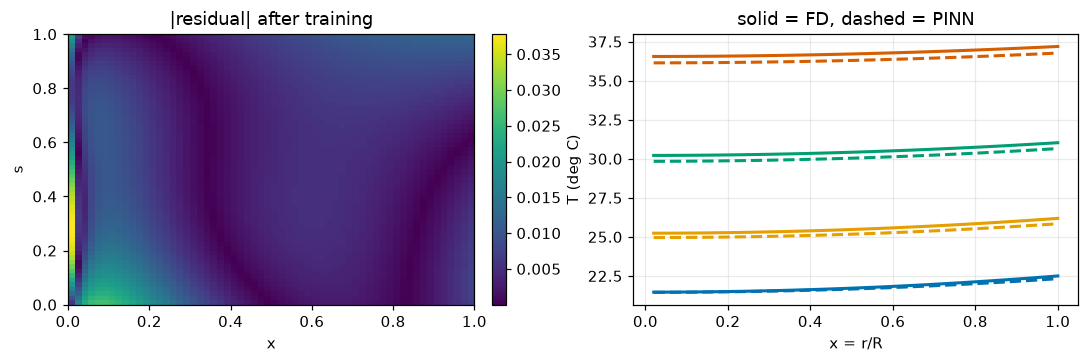

max|error| = 0.563 deg C   RMSE = 0.328 deg C


In [48]:
# Residual map after training, plus profile overlays at a few times.
R_c = residual_cyl(pinn_c, torch.tensor(np.stack([Xg.ravel(), Sg.ravel()], 1),
                                        dtype=torch.float32)).detach().numpy().reshape(60,60)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
heat(ax[0], np.abs(R_c), [0,1,0,1], "|residual| after training", "viridis", "x", "s")
for i, ts0 in enumerate([0.1, 0.3, 0.6, 1.0]):
    k = np.argmin(np.abs(sg - ts0))
    ax[1].plot(xg, T_ref[k],  color=CB[i], lw=2)         # solid = FD
    ax[1].plot(xg, T_pred[k], "--", color=CB[i], lw=2)   # dashed = PINN
ax[1].set_xlabel("x = r/R"); ax[1].set_ylabel("T (deg C)")
ax[1].set_title("solid = FD, dashed = PINN"); plt.tight_layout(); plt.show()

e = np.abs(T_pred - T_ref)
print(f"max|error| = {e.max():.3f} deg C   RMSE = {np.sqrt((e**2).mean()):.3f} deg C")

The takeaway from Example 2 is the accounting table above, not the temperature field. Three functions carried over untouched. The physics lives entirely in `residual_cyl` and two boundary terms. Most PINN infrastructure is reusable, the governing equations are what change.

## 7. Example 3: a 2D plate

Same framework, one more spatial dimension. Transient conduction on a unit square with a source:

$$\frac{\partial T}{\partial t}=\alpha\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\right)+q(x,y,t),\qquad (x,y)\in[0,1]^2 .$$

We manufacture a solution again so the reference is exact:

$$T^\star=e^{-t}\sin(\pi x)\sin(\pi y)+\beta\,x(1-x)\,y(1-y),$$

zero on all four edges. The full list of changes from the 1D build:

- the network input goes from 2 to 3 (add $y$),
- the residual gains one term, $T_{yy}$,
- the boundary is four edges instead of two endpoints.

`MLP`, `grad`, `train_pinn`, the loss structure, and the plotting helpers are the same. Moving from 1D to 2D changes surprisingly little.

In [49]:
# Manufactured 2D solution and its source.
def T_exact2(x, y, t): return np.exp(-t)*np.sin(np.pi*x)*np.sin(np.pi*y) + beta*x*(1-x)*y*(1-y)
def T_ic2(x, y):        return np.sin(np.pi*x)*np.sin(np.pi*y) + beta*x*(1-x)*y*(1-y)
def q2(x, y, t):
    return (torch.exp(-t)*torch.sin(np.pi*x)*torch.sin(np.pi*y)*(2*alpha*np.pi**2 - 1)
            + 2*alpha*beta*(x*(1-x) + y*(1-y)))

set_seed(0)
Nc2, Ni2, Nb2 = 2500, 400, 120

# Interior points (x,y,t) and initial points at t=0.
Xc2 = torch.rand(Nc2, 3)
xy  = torch.rand(Ni2, 2); Xic2 = torch.cat([xy, torch.zeros(Ni2, 1)], 1)
y2  = torch.tensor(T_ic2(xy[:,0:1].numpy(), xy[:,1:2].numpy()), dtype=torch.float32)

# Boundary points on the four edges.
def edge(n, which):
    ct = torch.rand(n, 2); z = torch.zeros(n,1); o = torch.ones(n,1)
    if which == "x0": return torch.cat([z, ct[:,0:1], ct[:,1:2]], 1)
    if which == "x1": return torch.cat([o, ct[:,0:1], ct[:,1:2]], 1)
    if which == "y0": return torch.cat([ct[:,0:1], z, ct[:,1:2]], 1)
    if which == "y1": return torch.cat([ct[:,0:1], o, ct[:,1:2]], 1)
Xb2 = torch.cat([edge(Nb2, w) for w in ["x0","x1","y0","y1"]], 0)

print("collocation:", tuple(Xc2.shape), "| IC:", tuple(Xic2.shape), "| boundary:", tuple(Xb2.shape))

collocation: (2500, 3) | IC: (400, 3) | boundary: (480, 3)


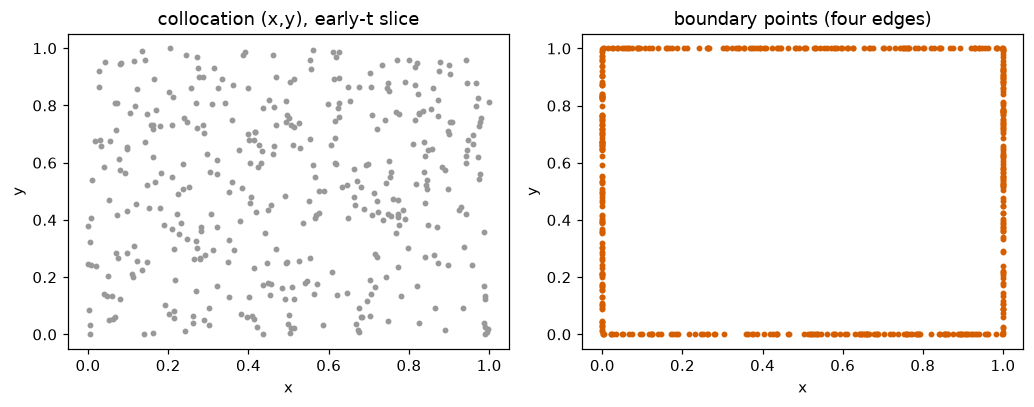

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))

# Left: interior points near the t=0 slice.
sl = Xc2[Xc2[:,2] < 0.15]
ax[0].scatter(sl[:,0], sl[:,1], s=8, color="0.6")
ax[0].set_title("collocation (x,y), early-t slice")
ax[0].set_xlabel("x"); ax[0].set_ylabel("y"); ax[0].grid(False)

# Right: the four boundary edges.
ax[1].scatter(Xb2[:,0], Xb2[:,1], s=8, color=CB[3])
ax[1].set_title("boundary points (four edges)")
ax[1].set_xlabel("x"); ax[1].set_ylabel("y"); ax[1].grid(False)
plt.tight_layout(); plt.show()

In [51]:
set_seed(0); pinn2 = MLP(3, 32, 3)          # only change from 1D: d_in = 3

# 2D residual: T_t - alpha*(T_xx + T_yy) - q.
def residual_2d(net, X):
    X = X.clone().requires_grad_(True)
    T = net(X); g = grad(T, X); T_x, T_y, T_t = g[:,0:1], g[:,1:2], g[:,2:3]
    T_xx = grad(T_x, X)[:,0:1]; T_yy = grad(T_y, X)[:,1:2]     # one extra term vs 1D
    return T_t - alpha*(T_xx + T_yy) - q2(X[:,0:1], X[:,1:2], X[:,2:3])

def loss_2d():
    L_pde = (residual_2d(pinn2, Xc2)**2).mean()
    L_ic  = ((pinn2(Xic2) - y2)**2).mean()
    L_bc  = (pinn2(Xb2)**2).mean()
    total = L_pde + 10*L_ic + 10*L_bc
    return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "total": total}

In [52]:
# Trains the 2D PINN: roughly 30 to 60 s on a Colab CPU.
# Same train_pinn loop as before.
t0 = time.time()
hist2 = train_pinn(pinn2, loss_2d, adam_iters=2500, lr=3e-3, lbfgs_iters=0)
print(f"trained in {time.time()-t0:.1f}s")

trained in 13.7s


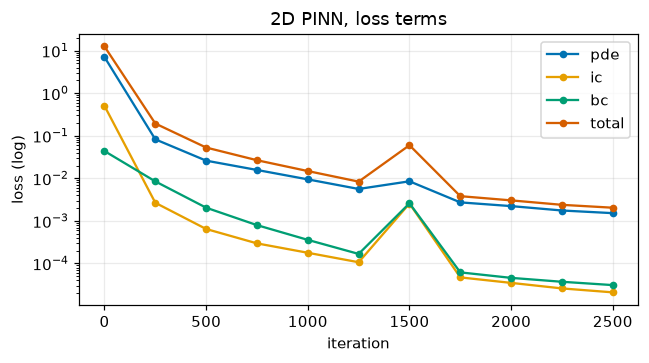

In [53]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for i, k in enumerate(["pde", "ic", "bc", "total"]):
    it, v = zip(*hist2[k]); ax.semilogy(it, v, "o-", color=CB[i], label=k, ms=4)
ax.set_xlabel("iteration"); ax.set_ylabel("loss (log)"); ax.legend()
ax.set_title("2D PINN, loss terms"); plt.tight_layout(); plt.show()

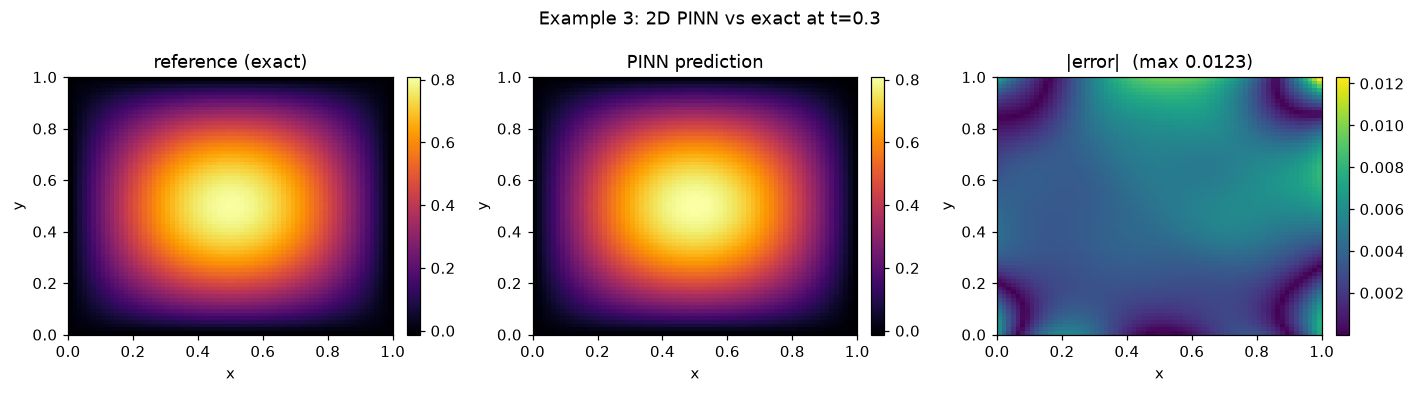

In [54]:
# Predict a single time slice and compare to the exact field.
ts = 0.3; m = 70; gg = np.linspace(0, 1, m); Xg, Yg = np.meshgrid(gg, gg)
grid2 = np.stack([Xg.ravel(), Yg.ravel(), np.full(m*m, ts)], 1).astype(np.float32)
with torch.no_grad():
    Fp2 = pinn2(torch.tensor(grid2)).numpy().reshape(m, m)
Fref2 = T_exact2(Xg, Yg, ts)

panels3(Fref2, Fp2, [0,1,0,1], f"Example 3: 2D PINN vs exact at t={ts}", "inferno", "x", "y")

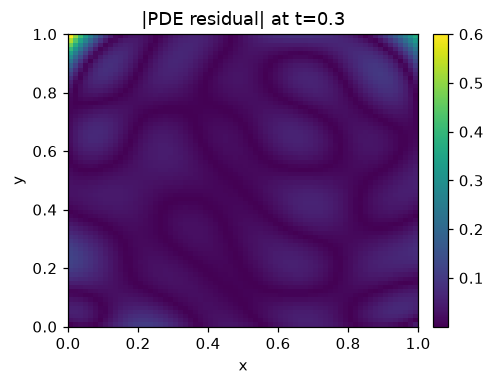

slice t=0.3:  max|error| = 0.0123   RMSE = 0.0044


In [55]:
Rr = residual_2d(pinn2, torch.tensor(grid2)).detach().numpy().reshape(m, m)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
heat(ax, np.abs(Rr), [0,1,0,1], f"|PDE residual| at t={ts}", "viridis", "x", "y")
plt.tight_layout(); plt.show()

e = np.abs(Fp2 - Fref2)
print(f"slice t={ts}:  max|error| = {e.max():.4f}   RMSE = {np.sqrt((e**2).mean()):.4f}")

The 2D residual and error maps look just like the 1D ones, small and structureless. The difference from Example 1 was three lines: an extra input, an extra second-derivative term, and edges in place of endpoints. That reuse is the argument for building the machinery carefully once.

## 8. The same problem in about 8 lines of DeepXDE

We built everything by hand so the mechanics are visible. In practice you would reach for a library. DeepXDE wraps the geometry, the point sampling, the residual bookkeeping, and the training loop. Here is the 1D rod again, matched to the hand-built run: same architecture ([2, 32, 32, 32, 1], `tanh`), same optimizer (Adam at 3e-3), same collocation budget. This is a reveal, not a result. Stage 2 is where DeepXDE does real work.

In [56]:
# Installs DeepXDE (needs a network connection). This can take a minute or two.
%pip install deepxde -q
import os
os.environ["DDE_BACKEND"] = "pytorch"     # force the PyTorch backend before importing
import deepxde as dde                      # if the backend does not switch, restart the runtime
torch.set_default_device("cpu")         # DeepXDE 1.15 makes the Apple GPU (MPS) the default device on import; it is slower here (4.4 vs 1.9 ms per Adam iteration), so I keep the CPU

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Note: you may need to restart the kernel to use updated packages.


In [57]:
# The whole 1D rod problem, expressed in DeepXDE.
def pde(X, T):
    T_t  = dde.grad.jacobian(T, X, i=0, j=1)
    T_xx = dde.grad.hessian(T, X, i=0, j=0)
    x, t = X[:, 0:1], X[:, 1:2]
    q = torch.exp(-t)*torch.sin(np.pi*x)*(alpha*np.pi**2 - 1) + 2*alpha*beta
    return T_t - alpha*T_xx - q

# Geometry in space and time, plus boundary and initial conditions.
gt = dde.geometry.GeometryXTime(dde.geometry.Interval(0, 1), dde.geometry.TimeDomain(0, 1))
bc = dde.icbc.DirichletBC(gt, lambda X: 0.0, lambda _, on_b: on_b)
ic = dde.icbc.IC(gt, lambda X: np.sin(np.pi*X[:,0:1]) + beta*X[:,0:1]*(1-X[:,0:1]),
                 lambda _, on_i: on_i)

# Data, model, and training: matched to the hand-built run.
data  = dde.data.TimePDE(gt, pde, [bc, ic], num_domain=2000, num_boundary=200, num_initial=200)
model = dde.Model(data, dde.nn.FNN([2] + [32]*3 + [1], "tanh", "Glorot normal"))
model.compile("adam", lr=3e-3)
model.train(iterations=3000, display_every=1000)   # roughly 20 to 40 s on a Colab CPU

Compiling model...
'compile' took 0.000161 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [4.56e+00, 1.33e-02, 9.19e-01]    [4.56e+00, 1.33e-02, 9.19e-01]    []  


1000      [1.30e-04, 1.79e-05, 8.52e-06]    [1.30e-04, 1.79e-05, 8.52e-06]    []  


2000      [3.48e-05, 1.73e-06, 5.01e-07]    [3.48e-05, 1.73e-06, 5.01e-07]    []  


3000      [1.30e-04, 2.06e-04, 1.74e-04]    [1.30e-04, 2.06e-04, 1.74e-04]    []  



Best model at step 2000:
  train loss: 3.70e-05
  test loss: 3.70e-05
  test metric: []

'train' took 11.051165 s



(<deepxde.model.LossHistory at 0x12c0b6cf0>,
 <deepxde.model.TrainState at 0x12c156c00>)

DeepXDE: max|error| = 0.0204   RMSE = 0.0150


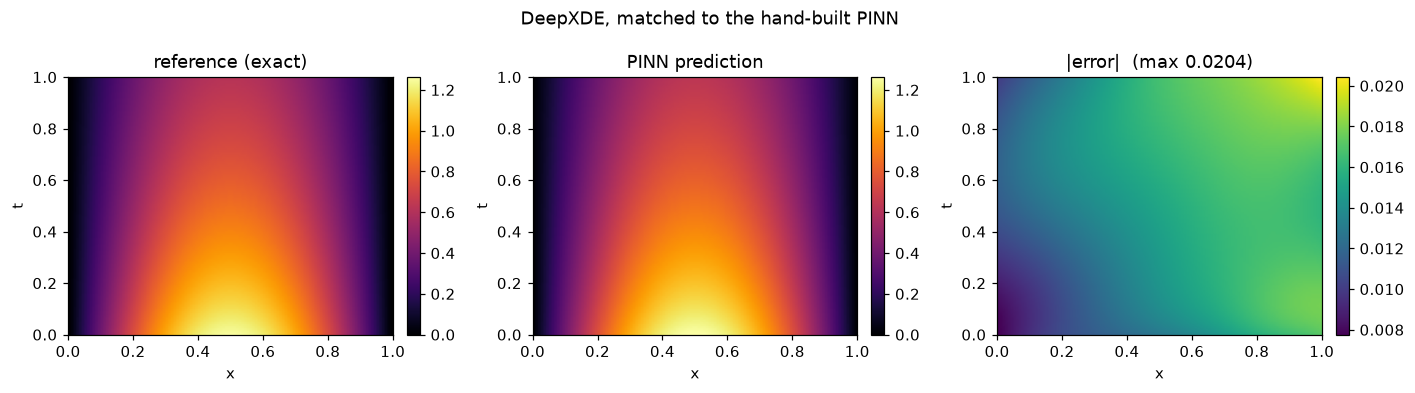

In [58]:
Fdde = model.predict(np.stack([XX.ravel(), TT.ravel()], 1).astype(np.float32)).reshape(nt, nx)
e = np.abs(Fdde - Fexact)
print(f"DeepXDE: max|error| = {e.max():.4f}   RMSE = {np.sqrt((e**2).mean()):.4f}")
panels3(Fexact, Fdde, [0,1,0,1], "DeepXDE, matched to the hand-built PINN", "inferno", "x", "t")

The two implementations were matched, same network, optimizer, and collocation budget, so the results compare directly. The library reproduces the hand-built accuracy in a fraction of the code. What it hides is exactly what Sections 3 to 5 made visible: the points, the residual, the loss terms.

**On to Stage 2:** we keep DeepXDE, hold a set of measurements fixed, and solve for an unknown physical parameter instead of the field. That is the inverse problem.

## Takeaways

- A PINN is a small network plus autograd derivatives. The PDE becomes a residual, and training drives that residual to zero at a cloud of collocation points, while separate terms pin down the initial and boundary data.
- The loss weights are not decoration. Under-weight the IC or BC and the network solves a nearby wrong problem with a small residual. Watch the residual field and the error field together.
- Scaling is not optional. Real units wreck the conditioning of the optimization, and a PINN feels that like any other numerical method. Non-dimensionalize, and useful groups like the Fourier and Biot numbers fall out for free.
- Almost none of the code changes between problems. The `MLP`, the `grad` helper, and `train_pinn` were reused unchanged across a 1D rod, a cylindrical pin, and a 2D plate. Only the residual and the boundary terms moved.
- Smooth activations matter. Second-order PDEs need a second derivative, and `tanh` has one. `ReLU` silently does not.

## Experiment: change this and rerun

- In Example 1, change $\beta$ or the manufactured field and re-derive $q$ (the source is just $T_t-\alpha T_{xx}$). Watch the error map.
- Push the loss weights in Section 4.1 to extremes and see the network abandon the boundary or the initial condition.
- In Example 2, set $t_f=10$ s and re-run. The transient flattens and the problem gets easier and less interesting. Or shrink `xmin` toward the axis and watch the $1/x$ term destabilize training.
- In Example 3, predict a different time slice, or raise `Nc2`.
- Swap the Adam-then-L-BFGS schedule for Adam alone on the cylinder and compare the final residual.

# My runs of the five experiments
I ran the five experiments of the closing section with the notebook's own pieces: `quick_pinn` and `train_pinn` (Example 1), the cylinder residual, loss and finite-difference reference `fd_cylinder` (Example 2), and the 2D plate (`residual_2d`, `T_exact2`, `pinn2`, Example 3). Everything runs on the CPU with two threads. I kept each sweep to at most three new settings: ten trainings in all.

In [59]:
torch.set_default_device("cpu")   # the hand-built networks run on the CPU (this resets the default device the DeepXDE section may have changed)
import pandas as pd
from pathlib import Path
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True)
ex_beta0 = beta

## Experiment 1 — a different manufactured field ($\beta$)
The source $q = T_t - \alpha T_{xx}$ already contains $\beta$ (`pde_residual` and `q_src` use the global `beta`), so changing $\beta$ re-derives $q$ automatically. I run `quick_pinn` (the Section 4 trainer) for $\beta$ = 0, 1 (the base case) and 3.

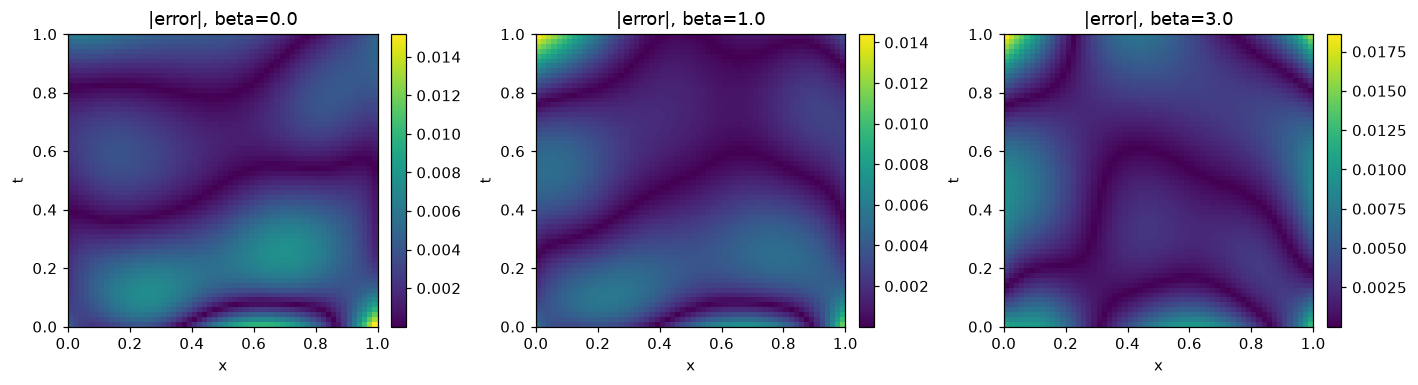

   beta   max_err      rmse   T_range  rel_rmse
0   0.0  0.015173  0.003557  0.999646  0.003558
1   1.0  0.014407  0.002985  1.249574  0.002388
2   3.0  0.018602  0.003798  1.749430  0.002171
Result (Experiment 1): quick_pinn RMSE (relative to the field range) beta=0: 0.0036 (0.36 %); beta=1: 0.0030 (0.24 %); beta=3: 0.0038 (0.22 %)


In [60]:
ex1_rows = []; fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for k, b_ in enumerate((0.0, 1.0, 3.0)):
    beta = b_
    res = quick_pinn()
    if b_ == 1.0: ex_res_base = res   # the Section 4 defaults (weights 10 and 10): baseline row of Experiment 2
    ex1_rows.append(dict(beta=b_, max_err=res["max_err"], rmse=res["rmse"], T_range=float(np.ptp(res["ref"]))))
    heat(axs[k], np.abs(res["Fp"] - res["ref"]), [0, 1, 0, 1], f"|error|, beta={b_}", "viridis", "x", "t")
beta = ex_beta0
plt.tight_layout(); plt.savefig(ex_dir / "exp1_beta_error_maps.png", dpi=100); plt.show()
ex1 = pd.DataFrame(ex1_rows); ex1["rel_rmse"] = ex1.rmse / ex1.T_range; ex1.to_csv(ex_dir / "exp1_beta.csv", index=False); print(ex1)
print("Result (Experiment 1): quick_pinn RMSE (relative to the field range) " + "; ".join(f"beta={r.beta:g}: {r.rmse:.4f} ({100*r.rel_rmse:.2f} %)" for r in ex1.itertuples()))

## Experiment 2 — extreme loss weights
I run `quick_pinn` with $(\lambda_{ic}, \lambda_{bc})$ = (0.01, 0.01), (1000, 1000) and (0.01, 1000); the (10, 10) row is the $\beta$ = 1 run of Experiment 1, not retrained. For each I report the final value of each loss term and the error against the exact field.

In [61]:
ex2_rows = []
for li, lb in ((10, 10), (0.01, 0.01), (1000, 1000), (0.01, 1000)):
    res = ex_res_base if (li, lb) == (10, 10) else quick_pinn(lam_ic=li, lam_bc=lb)
    ex2_rows.append(dict(lam_ic=li, lam_bc=lb, pde=res["hist"]["pde"][-1][1], ic=res["hist"]["ic"][-1][1], bc=res["hist"]["bc"][-1][1], max_err=res["max_err"], rmse=res["rmse"]))
ex2 = pd.DataFrame(ex2_rows); ex2.to_csv(ex_dir / "exp2_loss_weights.csv", index=False); print(ex2)
print("Result (Experiment 2): RMSE " + "; ".join(f"(ic {r.lam_ic:g}, bc {r.lam_bc:g}): {r.rmse:.3f} [ic loss {r.ic:.1e}, bc loss {r.bc:.1e}]" for r in ex2.itertuples()))

    lam_ic   lam_bc       pde        ic        bc   max_err      rmse
0    10.00    10.00  0.001828  0.000024  0.000032  0.014407  0.002985
1     0.01     0.01  0.000803  0.303946  0.241753  0.721931  0.312850
2  1000.00  1000.00  0.708344  0.000576  0.000349  0.166408  0.060659
3     0.01  1000.00  4.347953  0.837947  0.000033  1.256511  0.634270
Result (Experiment 2): RMSE (ic 10, bc 10): 0.003 [ic loss 2.4e-05, bc loss 3.2e-05]; (ic 0.01, bc 0.01): 0.313 [ic loss 3.0e-01, bc loss 2.4e-01]; (ic 1000, bc 1000): 0.061 [ic loss 5.8e-04, bc loss 3.5e-04]; (ic 0.01, bc 1000): 0.634 [ic loss 8.4e-01, bc loss 3.3e-05]


With tiny weights the network satisfies the PDE (small residual) but ignores the initial and boundary data, so it converges to a different solution of the same equation; with one weight tiny and the other huge it abandons the under-weighted condition (its loss stays large); very large weights on both make the PDE term relatively negligible early in training.

## Experiments 3 and 5 — the cylinder: longer window, smaller axis cut-off, optimiser schedule
I wrote a helper that rebuilds the cylindrical PINN of Example 2 for a given time window $t_f$ (which changes the Fourier number Fo and the source group S) and axis cut-off `xmin`, trains it with the notebook's schedule (2,500 Adam iterations, then 25 L-BFGS) or with Adam only, and compares it with `fd_cylinder` for the same window, in degrees Celsius.

In [62]:
from scipy.interpolate import RegularGridInterpolator
def ex_cyl(tf_=2.0, xmin_=0.02, lbfgs=25, seed=0):
    Fo_ = D * tf_ / R**2; S_ = Qvol * tf_ / (Tfl - T0)
    set_seed(seed)
    xc = torch.rand(Nc, 1) * (1 - xmin_) + xmin_; X_ = torch.cat([xc, torch.rand(Nc, 1)], 1)
    xi_ = torch.rand(Ni, 1); Xi_ = torch.cat([xi_, torch.zeros_like(xi_)], 1)
    sa_ = torch.rand(Na, 1); Xa_ = torch.cat([torch.zeros_like(sa_), sa_], 1)
    sw_ = torch.rand(Nw, 1); Xw_ = torch.cat([torch.ones_like(sw_), sw_], 1)
    set_seed(seed); net = MLP(2, 32, 3)
    def res_(X):
        X = X.clone().requires_grad_(True); th = net(X); g = grad(th, X)
        return g[:, 1:2] - Fo_ * (grad(g[:, 0:1], X)[:, 0:1] + g[:, 0:1] / X[:, 0:1]) - S_
    def loss_():
        L_pde = (res_(X_) ** 2).mean(); L_ic = (net(Xi_) ** 2).mean()
        Xa = Xa_.clone().requires_grad_(True); L_ax = (grad(net(Xa), Xa)[:, 0:1] ** 2).mean()
        Xw = Xw_.clone().requires_grad_(True); thw = net(Xw); L_w = ((grad(thw, Xw)[:, 0:1] - Bi * (1 - thw)) ** 2).mean()
        total = L_pde + 10 * L_ic + 10 * L_ax + 10 * L_w
        return total, {"pde": L_pde, "ic": L_ic, "ax": L_ax, "wall": L_w, "total": total}
    t0 = time.time(); h = train_pinn(net, loss_, adam_iters=2500, lr=3e-3, lbfgs_iters=lbfgs); tt = time.time() - t0
    rf, tfd, Tfd = fd_cylinder(tf=tf_)
    xs_, ss_ = np.meshgrid(rf / R, tfd / tf_)
    with torch.no_grad(): th = net(torch.tensor(np.stack([xs_.ravel(), ss_.ravel()], 1), dtype=torch.float32)).numpy().reshape(xs_.shape)
    Tp = T0 + th * (Tfl - T0); e = np.abs(Tp - Tfd)
    Xr = torch.tensor(np.stack([np.linspace(max(xmin_, 1e-3), 1, 60).repeat(60), np.tile(np.linspace(0, 1, 60), 60)], 1), dtype=torch.float32)
    return dict(tf=tf_, xmin=xmin_, lbfgs=lbfgs, Fo=Fo_, S=S_, rmse_K=float(np.sqrt((e ** 2).mean())), max_err_K=float(e.max()),
                T_rise_K=float(Tfd.max() - T0), final_pde_loss=h["pde"][-1][1], mean_abs_residual=float(res_(Xr).abs().mean()), train_s=round(tt, 1))
ex_cyl_base = ex_cyl()   # the notebook's settings with this helper's points: shared baseline of Experiments 3 and 5
ex3 = pd.DataFrame([ex_cyl_base, ex_cyl(tf_=10.0), ex_cyl(xmin_=0.005), ex_cyl(xmin_=0.001)]); ex3.to_csv(ex_dir / "exp3_cylinder.csv", index=False); print(ex3.round(4))
print("Result (Experiment 3): cylinder RMSE vs FD (K) " + "; ".join(f"tf={r.tf:g} s, xmin={r.xmin:g}: {r.rmse_K:.3f} (temperature rise {r.T_rise_K:.2f} K)" for r in ex3.itertuples()))

     tf   xmin  lbfgs       Fo       S  rmse_K  max_err_K  T_rise_K  \
0   2.0  0.020     25   2.7425  0.1870  0.3270     0.5631   17.1896   
1  10.0  0.020     25  13.7123  0.9349  9.4564    11.1940   50.5841   
2   2.0  0.005     25   2.7425  0.1870  0.2026     0.6042   17.1896   
3   2.0  0.001     25   2.7425  0.1870  0.1799     0.6766   17.1896   

   final_pde_loss  mean_abs_residual  train_s  
0          0.0000             0.0055     11.6  
1          0.0076             0.0754     11.7  
2          0.0001             0.0102     11.4  
3          0.0002             0.0141     10.9  
Result (Experiment 3): cylinder RMSE vs FD (K) tf=2 s, xmin=0.02: 0.327 (temperature rise 17.19 K); tf=10 s, xmin=0.02: 9.456 (temperature rise 50.58 K); tf=2 s, xmin=0.005: 0.203 (temperature rise 17.19 K); tf=2 s, xmin=0.001: 0.180 (temperature rise 17.19 K)


In [63]:
ex5 = pd.DataFrame([dict(schedule="Adam 2500 + L-BFGS 25 (base)", **ex_cyl_base), dict(schedule="Adam 2500 only", **ex_cyl(lbfgs=0))])
ex5.to_csv(ex_dir / "exp5_cylinder_optimizer.csv", index=False); print(ex5[["schedule", "final_pde_loss", "mean_abs_residual", "rmse_K"]])
print("Result (Experiment 5): final PDE loss / RMSE vs FD: " + "; ".join(f"{r.schedule}: {r.final_pde_loss:.2e} / {r.rmse_K:.3f} K" for r in ex5.itertuples()))

                       schedule  final_pde_loss  mean_abs_residual    rmse_K
0  Adam 2500 + L-BFGS 25 (base)        0.000045           0.005463  0.326971
1                Adam 2500 only        0.000058           0.006466  0.146491
Result (Experiment 5): final PDE loss / RMSE vs FD: Adam 2500 + L-BFGS 25 (base): 4.54e-05 / 0.327 K; Adam 2500 only: 5.84e-05 / 0.146 K


With $t_f$ = 10 s the window is long compared with the lumped time constant and the pin approaches its steady state; in the table above this case has by far the largest error, so the longer window does not make the problem easier for this network and schedule. Moving `xmin` toward the axis puts collocation points where the $\theta_x/x$ term of the residual becomes singular; the error and the residual show whether training tolerates it. Dropping the 25 L-BFGS iterations leaves the final residual at the level Adam reached.

## Experiment 4 — the 2D plate: other time slices and more collocation points
I evaluate the trained `pinn2` of Example 3 at $t$ = 0.0, 0.3 (the slice shown above), 0.7 and 1.0, and train a new 2D PINN with `Nc2` = 6,000 interior points (2,500 in Example 3), same schedule, compared on the same slices.

In [64]:
def ex_slice_err(net, ts_):
    m = 70; gg = np.linspace(0, 1, m); Xg, Yg = np.meshgrid(gg, gg)
    g2 = np.stack([Xg.ravel(), Yg.ravel(), np.full(m * m, ts_)], 1).astype(np.float32)
    with torch.no_grad(): Fp = net(torch.tensor(g2)).numpy().reshape(m, m)
    return float(np.sqrt(((Fp - T_exact2(Xg, Yg, ts_)) ** 2).mean()))
set_seed(0); Xc2_big = torch.rand(6000, 3)
set_seed(0); ex_pinn2b = MLP(3, 32, 3)
def ex_loss_2d_big():
    L_pde = (residual_2d(ex_pinn2b, Xc2_big) ** 2).mean(); L_ic = ((ex_pinn2b(Xic2) - y2) ** 2).mean(); L_bc = (ex_pinn2b(Xb2) ** 2).mean()
    total = L_pde + 10 * L_ic + 10 * L_bc
    return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "total": total}
t0 = time.time(); train_pinn(ex_pinn2b, ex_loss_2d_big, adam_iters=2500, lr=3e-3, lbfgs_iters=0); ex4_t = time.time() - t0
ex4 = pd.DataFrame([dict(t=ts_, rmse_Nc2_2500=ex_slice_err(pinn2, ts_), rmse_Nc2_6000=ex_slice_err(ex_pinn2b, ts_)) for ts_ in (0.0, 0.3, 0.7, 1.0)])
ex4.to_csv(ex_dir / "exp4_plate.csv", index=False); print(ex4)
print("Result (Experiment 4): 2D plate RMSE by time slice (Nc2 2500 / 6000): " + "; ".join(f"t={r.t:g}: {r.rmse_Nc2_2500:.4f} / {r.rmse_Nc2_6000:.4f}" for r in ex4.itertuples()) + f" ({ex4_t:.0f} s for the 6000-point training)")

     t  rmse_Nc2_2500  rmse_Nc2_6000
0  0.0       0.005021       0.081681
1  0.3       0.004353       0.083747
2  0.7       0.002068       0.094740
3  1.0       0.004532       0.099595
Result (Experiment 4): 2D plate RMSE by time slice (Nc2 2500 / 6000): t=0: 0.0050 / 0.0817; t=0.3: 0.0044 / 0.0837; t=0.7: 0.0021 / 0.0947; t=1: 0.0045 / 0.0996 (22 s for the 6000-point training)


## Summary of the experiments
The numbers are in the `Result` lines above; the tables and figures are in `../results/01_pinn_heat_conduction_from_scratch/exercises/`.

# Training animation — the PINN learning the rod's temperature
The hook attached before training recorded Example 1's PINN (`MLP(2, 32, 3)`, weights 10 and 10, 2,500 Adam iterations at 3e-3, then 25 L-BFGS iterations, seed 0) as it trained, so the animation comes from the same run, not a second one. Every 50 Adam iterations (and after L-BFGS) it stored the loss terms and the predicted field on the 120×120 grid. Video: `../animations/01_training_dashboard.mp4`; last frame: `../animations/01_final_frame.png`.

In [65]:
import pickle
torch.set_default_device("cpu")
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = ANIM_DIR; anim_dir.mkdir(exist_ok=True)
snaps = anim_snaps
pickle.dump(snaps, open(anim_dir / f"{ANIM_PREFIX}snapshots.pkl", "wb"))
e_ = np.abs(snaps[-1]["F"] - Fexact); print(f"Last snapshot: max|error| {e_.max():.4f}, RMSE {np.sqrt((e_**2).mean()):.4f}")

Last snapshot: max|error| 0.0028, RMSE 0.0005


In [66]:
vmn, vmx = Fexact.min(), Fexact.max(); emax = np.abs(snaps[len(snaps) // 4]["F"] - Fexact).max()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
def anim_draw(k):
    s_ = snaps[k]
    for a in axes: a.clear()
    for a_, F_, ttl, cm, lo, hi in ((axes[0], Fexact, "exact T(x,t)", "inferno", vmn, vmx), (axes[1], s_["F"], f"PINN, iteration {s_['it']}", "inferno", vmn, vmx),
                                    (axes[2], np.abs(s_["F"] - Fexact), "|error|", "viridis", 0, emax)):
        a_.imshow(F_, extent=[0, 1, 0, 1], origin="lower", aspect="auto", cmap=cm, vmin=lo, vmax=hi); a_.set_title(ttl); a_.set_xlabel("x"); a_.set_ylabel("t"); a_.grid(False)
    tr_ = np.array(s_["terms"]) if s_["terms"] else np.zeros((0, 3))
    for j, nm in enumerate(("pde", "ic", "bc")):
        if len(tr_): axes[3].semilogy(np.arange(1, len(tr_) + 1), tr_[:, j], color=CB[j], label=nm)
    axes[3].set_xlim(0, 2530); axes[3].set_ylim(1e-6, 1e3); axes[3].set_xlabel("iteration"); axes[3].legend(); axes[3].set_title("loss terms")
    fig.suptitle("Stage 1 — PINN for the 1D heat equation: training run"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / f"{ANIM_PREFIX}final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / f"{ANIM_PREFIX}training_dashboard.mp4", writer=FFMpegWriter(fps=10, bitrate=1600), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

Animation: 51 frames written


**What the animation shows.** The exact manufactured temperature field $T(x,t)$, the PINN's prediction at each snapshot, the absolute error, and the three loss terms; the last frame is after the final L-BFGS polish.

# Three seeds
I repeat every result above that depends on a random initialisation (the point sets and the network weights) with the seeds 0, 1 and 2: the Example 1 PINN, the physics-plus-data run, the cylindrical pin, the 2D plate, the DeepXDE rod, and the five experiments. Each row is one training run with the same settings as the run it repeats; the summaries give the mean and the standard deviation over the three seeds. Tables and the summary figure are in `../results/01_pinn_heat_conduction_from_scratch/exercises/`, the seed models in `../models/01_pinn_heat_conduction_from_scratch/`.

In [67]:
import pandas as pd, time
from pathlib import Path
torch.set_default_device("cpu")
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True)
MODELS = MODELS_DIR; MODELS.mkdir(exist_ok=True)
SEEDS = (0, 1, 2)
beta = ex_beta0                                  # the manufactured field of the main examples (beta = 1)
grid_full = torch.tensor(np.stack([XX.ravel(), TT.ravel()], 1), dtype=torch.float32)

def seeds_example1(seed):
    # Example 1: point sets and network drawn with the given seed, same settings
    set_seed(seed)
    Xc_ = torch.rand(Ncol, 2); xic_ = torch.rand(Nic, 1); Xic_ = torch.cat([xic_, torch.zeros_like(xic_)], 1)
    Tic_ = torch.tensor(T_ic(xic_.numpy()), dtype=torch.float32)
    tbc_ = torch.rand(Nbc, 1); Xb0_ = torch.cat([torch.zeros_like(tbc_), tbc_], 1); Xb1_ = torch.cat([torch.ones_like(tbc_), tbc_], 1)
    set_seed(seed); net = MLP(2, 32, 3)
    def loss_():
        L_pde = (pde_residual(net, Xc_)**2).mean(); L_ic = ((net(Xic_) - Tic_)**2).mean(); L_bc = (net(Xb0_)**2).mean() + (net(Xb1_)**2).mean()
        total = L_pde + lam_ic*L_ic + lam_bc*L_bc
        return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "total": total}
    t0 = time.time(); h = train_pinn(net, loss_, adam_iters=2500, lr=3e-3, lbfgs_iters=25); tt = time.time() - t0
    with torch.no_grad(): Fp_ = net(grid_full).numpy().reshape(nt, nx)
    e = np.abs(Fp_ - Fexact); torch.save(net.state_dict(), MODELS / f"pinn_ex1_seed{seed}.pth")
    return dict(case="Example 1 rod (2500 Adam + 25 L-BFGS)", seed=seed, max_err=float(e.max()), rmse=float(np.sqrt((e**2).mean())), final_pde_loss=h["pde"][-1][1], train_s=round(tt, 1))

def seeds_data(seed):
    # Section 5: the notebook's sensors (seed 3) and point sets, network drawn with the given seed
    set_seed(seed); net = MLP(2, 32, 3)
    def loss_():
        L_pde = (pde_residual(net, Xc)**2).mean(); L_ic = ((net(Xic) - Tic_target)**2).mean(); L_bc = (net(Xb0)**2).mean() + (net(Xb1)**2).mean()
        L_dat = ((net(Xdata) - ydata)**2).mean(); total = L_pde + lam_ic*L_ic + lam_bc*L_bc + lam_data*L_dat
        return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "data": L_dat, "total": total}
    t0 = time.time(); train_pinn(net, loss_, adam_iters=2000, lr=3e-3, lbfgs_iters=20); tt = time.time() - t0
    with torch.no_grad(): Fp_ = net(grid_full).numpy().reshape(nt, nx); fit = (net(Xdata) - ydata).abs().mean().item()
    e = np.abs(Fp_ - Fexact); torch.save(net.state_dict(), MODELS / f"pinn_data_seed{seed}.pth")
    return dict(case="Example 1 physics + 12 sensors", seed=seed, max_err=float(e.max()), rmse=float(np.sqrt((e**2).mean())), sensor_fit=fit, train_s=round(tt, 1))

def seeds_plate(seed, nc=2500):
    # Example 3: points and network drawn with the given seed; nc interior points
    set_seed(seed); Xc_ = torch.rand(nc, 3); xy_ = torch.rand(Ni2, 2); Xic_ = torch.cat([xy_, torch.zeros(Ni2, 1)], 1)
    y_ = torch.tensor(T_ic2(xy_[:, 0:1].numpy(), xy_[:, 1:2].numpy()), dtype=torch.float32); Xb_ = torch.cat([edge(Nb2, w) for w in ["x0", "x1", "y0", "y1"]], 0)
    set_seed(seed); net = MLP(3, 32, 3)
    def loss_():
        L_pde = (residual_2d(net, Xc_)**2).mean(); L_ic = ((net(Xic_) - y_)**2).mean(); L_bc = (net(Xb_)**2).mean()
        total = L_pde + 10*L_ic + 10*L_bc
        return total, {"pde": L_pde, "ic": L_ic, "bc": L_bc, "total": total}
    t0 = time.time(); train_pinn(net, loss_, adam_iters=2500, lr=3e-3, lbfgs_iters=0); tt = time.time() - t0
    torch.save(net.state_dict(), MODELS / f"pinn_plate_nc{nc}_seed{seed}.pth")
    return dict(case=f"2D plate, {nc} interior points", seed=seed, nc2=nc, **{f"rmse_t{ts_:g}": ex_slice_err(net, ts_) for ts_ in (0.0, 0.3, 0.7, 1.0)}, train_s=round(tt, 1))

def seeds_dde(seed):
    # Section 8: the DeepXDE rod with a set seed
    dde.config.set_random_seed(seed)
    data_ = dde.data.TimePDE(gt, pde, [bc, ic], num_domain=2000, num_boundary=200, num_initial=200)
    model_ = dde.Model(data_, dde.nn.FNN([2] + [32]*3 + [1], "tanh", "Glorot normal")); model_.compile("adam", lr=3e-3)
    t0 = time.time(); model_.train(iterations=3000, display_every=100000); tt = time.time() - t0
    F_ = model_.predict(np.stack([XX.ravel(), TT.ravel()], 1).astype(np.float32)).reshape(nt, nx); e = np.abs(F_ - Fexact)
    torch.set_default_device("cpu")
    return dict(case="DeepXDE rod (3000 Adam)", seed=seed, max_err=float(e.max()), rmse=float(np.sqrt((e**2).mean())), train_s=round(tt, 1))

rows_h = []
for s in SEEDS:
    rows_h += [seeds_example1(s), seeds_data(s), dict(case="cylindrical pin (2500 Adam + 25 L-BFGS)", seed=s, **{k: v for k, v in ex_cyl(seed=s).items() if k in ("rmse_K", "max_err_K", "final_pde_loss", "train_s")}),
               seeds_plate(s, 2500), seeds_dde(s)]
    print(f"seed {s} done")
seeds_head = pd.DataFrame(rows_h); seeds_head.to_csv(ex_dir / "seeds_headline_runs.csv", index=False)
cols = [c for c in ("max_err", "rmse", "rmse_K", "max_err_K", "sensor_fit", "rmse_t0", "rmse_t0.3", "rmse_t0.7", "rmse_t1", "final_pde_loss", "train_s") if c in seeds_head]
seeds_head_summary = seeds_head.groupby("case", sort=False)[cols].agg(["mean", "std"]); seeds_head_summary.columns = [f"{a}_{b}" for a, b in seeds_head_summary.columns]
seeds_head_summary.to_csv(ex_dir / "seeds_headline_summary.csv"); print(seeds_head.round(5).to_string()); print(seeds_head_summary.round(5).to_string())

Compiling model...
'compile' took 0.000163 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [4.92e+00, 3.11e-03, 7.67e-01]    [4.92e+00, 3.11e-03, 7.67e-01]    []  


3000      [3.27e-05, 5.66e-06, 5.38e-06]    [3.27e-05, 5.66e-06, 5.38e-06]    []  



Best model at step 3000:
  train loss: 4.37e-05
  test loss: 4.37e-05
  test metric: []

'train' took 11.933773 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


0         [5.50e+00, 4.95e-02, 9.14e-01]    [5.50e+00, 4.95e-02, 9.14e-01]    []  


3000      [5.44e-04, 5.22e-04, 5.06e-04]    [5.44e-04, 5.22e-04, 5.06e-04]    []  



Best model at step 3000:
  train loss: 1.57e-03
  test loss: 1.57e-03
  test metric: []

'train' took 10.539976 s



seed 2 done
                                       case  seed  max_err     rmse  final_pde_loss  train_s  sensor_fit   rmse_K  max_err_K     nc2  rmse_t0  rmse_t0.3  rmse_t0.7  rmse_t1
0     Example 1 rod (2500 Adam + 25 L-BFGS)     0  0.00283  0.00055         0.00023      9.9         NaN      NaN        NaN     NaN      NaN        NaN        NaN      NaN
1            Example 1 physics + 12 sensors     0  0.01407  0.00283             NaN      8.2     0.00939      NaN        NaN     NaN      NaN        NaN        NaN      NaN
2   cylindrical pin (2500 Adam + 25 L-BFGS)     0      NaN      NaN         0.00005     11.4         NaN  0.32697    0.56307     NaN      NaN        NaN        NaN      NaN
3            2D plate, 2500 interior points     0      NaN      NaN             NaN     14.5         NaN      NaN        NaN  2500.0  0.00502    0.00435    0.00207  0.00453
4                   DeepXDE rod (3000 Adam)     0  0.00784  0.00140             NaN     11.9         NaN      NaN        Na

## Experiments 1 and 2 with three seeds
`quick_pinn` (800 Adam iterations) for β = 0, 1, 3 and for the four loss-weight settings, seeds 0, 1 and 2 (seed 0 repeats the runs above).

In [68]:
rows_q = []
for s in SEEDS:
    for b_ in (0.0, 1.0, 3.0):
        beta = b_; r = quick_pinn(seed=s)
        rows_q.append(dict(experiment="1 manufactured field", setting=f"beta={b_:g}", seed=s, rmse=r["rmse"], max_err=r["max_err"], rel_rmse=r["rmse"] / float(np.ptp(r["ref"]))))
    beta = ex_beta0
    for li, lb in ((10, 10), (0.01, 0.01), (1000, 1000), (0.01, 1000)):
        r = quick_pinn(lam_ic=li, lam_bc=lb, seed=s)
        rows_q.append(dict(experiment="2 loss weights", setting=f"ic {li:g}, bc {lb:g}", seed=s, rmse=r["rmse"], max_err=r["max_err"], pde_loss=r["hist"]["pde"][-1][1], ic_loss=r["hist"]["ic"][-1][1], bc_loss=r["hist"]["bc"][-1][1]))
    print(f"seed {s} done")
beta = ex_beta0
seeds_q = pd.DataFrame(rows_q); seeds_q.to_csv(ex_dir / "seeds_exp12_runs.csv", index=False); print(seeds_q.round(5).to_string())

seed 0 done


seed 1 done


seed 2 done
              experiment           setting  seed     rmse  max_err  rel_rmse  pde_loss  ic_loss  bc_loss
0   1 manufactured field            beta=0     0  0.00356  0.01517   0.00356       NaN      NaN      NaN
1   1 manufactured field            beta=1     0  0.00298  0.01441   0.00239       NaN      NaN      NaN
2   1 manufactured field            beta=3     0  0.00380  0.01860   0.00217       NaN      NaN      NaN
3         2 loss weights      ic 10, bc 10     0  0.00298  0.01441       NaN   0.00183  0.00002  0.00003
4         2 loss weights  ic 0.01, bc 0.01     0  0.31285  0.72193       NaN   0.00080  0.30395  0.24175
5         2 loss weights  ic 1000, bc 1000     0  0.06066  0.16641       NaN   0.70834  0.00058  0.00035
6         2 loss weights  ic 0.01, bc 1000     0  0.63427  1.25651       NaN   4.34795  0.83795  0.00003
7   1 manufactured field            beta=0     1  0.00483  0.02894   0.00483       NaN      NaN      NaN
8   1 manufactured field            beta=1 

## Experiments 3 and 5 with three seeds
The cylinder helper `ex_cyl` for the window and axis cut-off settings of Experiment 3 and the Adam-only schedule of Experiment 5, seeds 0, 1 and 2.

In [69]:
rows_c = []
for s in SEEDS:
    for tf_, xm, lb in ((2.0, 0.02, 25), (10.0, 0.02, 25), (2.0, 0.005, 25), (2.0, 0.001, 25), (2.0, 0.02, 0)):
        r = ex_cyl(tf_=tf_, xmin_=xm, lbfgs=lb, seed=s)
        rows_c.append(dict(experiment="3 window and axis cut-off" if lb else "5 optimiser schedule", setting=f"tf={tf_:g} s, xmin={xm:g}, L-BFGS {lb}", seed=s, rmse=r["rmse_K"], max_err=r["max_err_K"], final_pde_loss=r["final_pde_loss"], mean_abs_residual=r["mean_abs_residual"], T_rise_K=r["T_rise_K"], train_s=r["train_s"]))
    print(f"seed {s} done")
seeds_c = pd.DataFrame(rows_c); seeds_c.to_csv(ex_dir / "seeds_exp35_runs.csv", index=False); print(seeds_c.round(5).to_string())

seed 0 done


seed 1 done


seed 2 done
                   experiment                        setting  seed      rmse   max_err  final_pde_loss  mean_abs_residual  T_rise_K  train_s
0   3 window and axis cut-off   tf=2 s, xmin=0.02, L-BFGS 25     0   0.32697   0.56307         0.00005            0.00546  17.18961     10.4
1   3 window and axis cut-off  tf=10 s, xmin=0.02, L-BFGS 25     0   9.45641  11.19398         0.00755            0.07536  50.58409     10.5
2   3 window and axis cut-off  tf=2 s, xmin=0.005, L-BFGS 25     0   0.20262   0.60418         0.00015            0.01023  17.18961     10.2
3   3 window and axis cut-off  tf=2 s, xmin=0.001, L-BFGS 25     0   0.17989   0.67665         0.00023            0.01407  17.18961     10.3
4        5 optimiser schedule    tf=2 s, xmin=0.02, L-BFGS 0     0   0.14649   0.64904         0.00006            0.00647  17.18961     10.1
5   3 window and axis cut-off   tf=2 s, xmin=0.02, L-BFGS 25     1   0.23666   0.58626         0.00005            0.00576  17.18961     10.1
6

## Experiment 4 with three seeds
The 2D plate with 2,500 and 6,000 interior points (points and network drawn with each seed; the 2,500-point seed-0 run repeats Example 3), scored on the four time slices.

In [70]:
rows_p = []
for s in SEEDS:
    for nc in (2500, 6000):
        r = seeds_plate(s, nc); rows_p.append(dict(experiment="4 plate collocation", setting=f"{nc} interior points", seed=s, rmse=r["rmse_t0.3"], **{k: v for k, v in r.items() if k.startswith("rmse_t") or k == "train_s"}))
    print(f"seed {s} done")
seeds_p = pd.DataFrame(rows_p); seeds_p.to_csv(ex_dir / "seeds_exp4_runs.csv", index=False); print(seeds_p.round(5).to_string())

seed 0 done


seed 1 done


seed 2 done
            experiment               setting  seed     rmse  rmse_t0  rmse_t0.3  rmse_t0.7  rmse_t1  train_s
0  4 plate collocation  2500 interior points     0  0.00435  0.00502    0.00435    0.00207  0.00453     12.9
1  4 plate collocation  6000 interior points     0  0.00494  0.00632    0.00494    0.00259  0.00513     19.7
2  4 plate collocation  2500 interior points     1  0.00255  0.00335    0.00255    0.00143  0.00285     13.0
3  4 plate collocation  6000 interior points     1  0.00321  0.00393    0.00321    0.00212  0.00439     19.9
4  4 plate collocation  2500 interior points     2  0.00521  0.00648    0.00521    0.00209  0.00294     12.8
5  4 plate collocation  6000 interior points     2  0.03327  0.02750    0.03327    0.02986  0.03486     18.4


## Summary over the three seeds

                                                         rmse_mean  rmse_std  max_err_mean  max_err_std  n_seeds
experiment                setting                                                                               
1 manufactured field      beta=0                           0.00653   0.00409       0.02564      0.00927        3
                          beta=1                           0.02087   0.02556       0.03968      0.02645        3
                          beta=3                           0.00480   0.00134       0.02086      0.00304        3
2 loss weights            ic 10, bc 10                     0.02087   0.02556       0.03968      0.02645        3
                          ic 0.01, bc 0.01                 0.23383   0.07226       0.55368      0.14963        3
                          ic 1000, bc 1000                 0.04633   0.02097       0.11033      0.06210        3
                          ic 0.01, bc 1000                 0.55739   0.13074       1.14539      

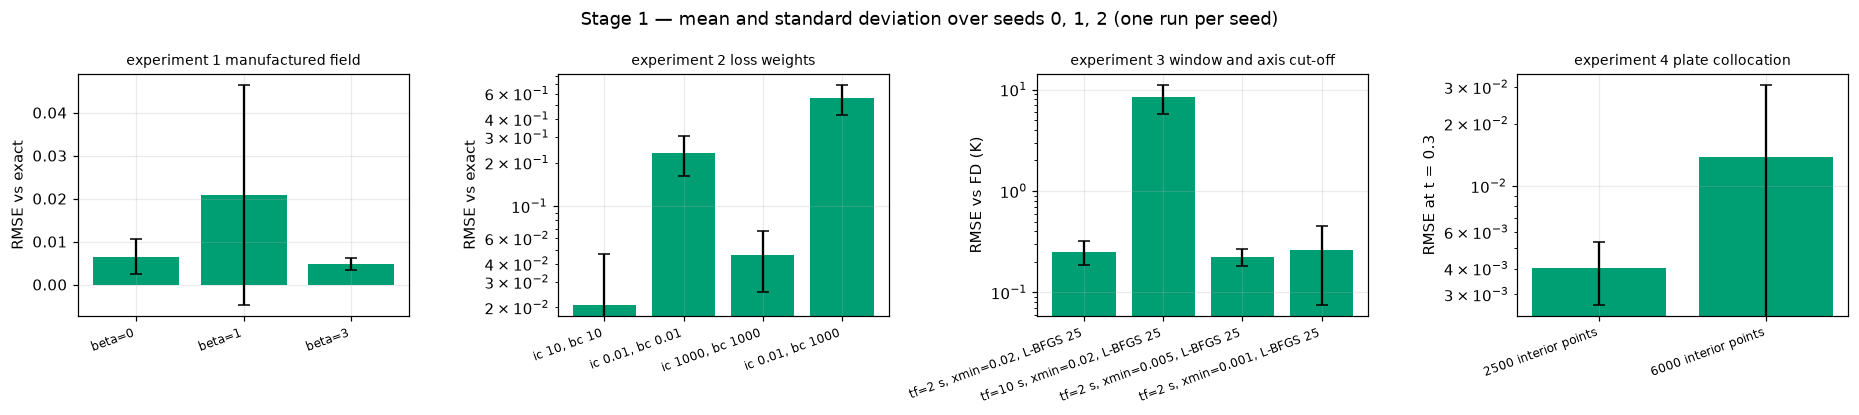

Result (three seeds): 1 manufactured field / beta=0: 0.0065 ± 0.0041; 1 manufactured field / beta=1: 0.0209 ± 0.0256; 1 manufactured field / beta=3: 0.0048 ± 0.0013; 2 loss weights / ic 10, bc 10: 0.0209 ± 0.0256; 2 loss weights / ic 0.01, bc 0.01: 0.2338 ± 0.0723; 2 loss weights / ic 1000, bc 1000: 0.0463 ± 0.0210; 2 loss weights / ic 0.01, bc 1000: 0.5574 ± 0.1307; 3 window and axis cut-off / tf=2 s, xmin=0.02, L-BFGS 25: 0.2528 ± 0.0676; 3 window and axis cut-off / tf=10 s, xmin=0.02, L-BFGS 25: 8.4075 ± 2.6773; 3 window and axis cut-off / tf=2 s, xmin=0.005, L-BFGS 25: 0.2262 ± 0.0441; 3 window and axis cut-off / tf=2 s, xmin=0.001, L-BFGS 25: 0.2614 ± 0.1857; 5 optimiser schedule / tf=2 s, xmin=0.02, L-BFGS 0: 0.3059 ± 0.2029; 4 plate collocation / 2500 interior points: 0.0040 ± 0.0014; 4 plate collocation / 6000 interior points: 0.0138 ± 0.0169


In [71]:
seeds_all = pd.concat([seeds_q, seeds_c, seeds_p], ignore_index=True)
summ = seeds_all.groupby(["experiment", "setting"], sort=False)[["rmse", "max_err"]].agg(["mean", "std"]); summ.columns = [f"{a}_{b}" for a, b in summ.columns]
summ["n_seeds"] = seeds_all.groupby(["experiment", "setting"], sort=False).size(); summ.to_csv(ex_dir / "seeds_experiments_summary.csv"); print(summ.round(5).to_string())
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, ylab, logy) in zip(axs, (("1 manufactured field", "RMSE vs exact", False), ("2 loss weights", "RMSE vs exact", True), ("3 window and axis cut-off", "RMSE vs FD (K)", True), ("4 plate collocation", "RMSE at t = 0.3", True))):
    g = summ.loc[name]; ax.bar(range(len(g)), g["rmse_mean"], yerr=g["rmse_std"], color=CB[2], capsize=4)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=20, ha="right", fontsize=8); ax.set_ylabel(ylab); ax.set_title(f"experiment {name}", fontsize=9)
    if logy: ax.set_yscale("log")
fig.suptitle("Stage 1 — mean and standard deviation over seeds 0, 1, 2 (one run per seed)"); plt.tight_layout(); plt.savefig(ex_dir / "seeds_summary.png", dpi=100); plt.show()
print("Result (three seeds): " + "; ".join(f"{i[0]} / {i[1]}: {r.rmse_mean:.4f} ± {r.rmse_std:.4f}" for i, r in summ.iterrows()))